# The Goal

1. Investigate the temporal ocupacie of high level RFI;
2. Determine the bandwith and corrupted channels.

In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm, colors as mcolors

import imageio # to collect frames and write them into an animated file.
import os
from PIL import Image
import io

import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models


# Read and convert to xarray

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [2]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Let's print the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(path, "r") as f:

    f.visititems(print_hdf5_structure)

    f.close()  # close the file



Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

In [3]:

# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]


datasets = []

with h5py.File(path, 'r') as f:
    for g in groups:
        
        # Load datasets correctly
        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]       # shape (n_time, n_freq)
        frequency = f[f"{g}/frequency"][1600:-60]/ 1e9
        time      = f[f"{g}/timestamp"][30:,0]     # often 2D


        # Construct xarray dataset
        ds = xr.Dataset(
            {
                "spectrum": (("time", "frequency"), spectrum)
            },
            coords={
                "time": time,
                "frequency": frequency
            },
            attrs={
                "description": f"Spectrum data of {g}",
                "units": {
                    "spectrum": "dB",
                    "frequency": "GHz",
                    "time": "UTC"
                }
            }
        )

        ds = ds.expand_dims({"group": [g]})  # add group dimension

        datasets.append(ds)
    f.close() # close the file

datasets

[<xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND0'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 1.883e+11 ... 4.159e+09
 Attributes:
     description:  Spectrum data of scan/000/P1_ND0
     units:        {'spectrum': 'dB', 'frequency': 'GHz', 'time': 'UTC'},
 <xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND1'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 6.967e+10 ... 1.648e+09
 Attributes:
     description:  Spectrum da

In [4]:
ds_nd0 = datasets[1]
spectrum = ds_nd0['spectrum']
spectrum

<xarray.DataArray 'spectrum' (group: 1, time: 634, frequency: 63877)> Size: 162MB
array([[[6.9667774e+10, 6.9684863e+10, 6.8958618e+10, ...,
         1.7127766e+09, 1.6890138e+09, 1.6748283e+09],
        [7.5376353e+10, 7.0926967e+10, 7.6868469e+10, ...,
         1.7694952e+09, 1.7671506e+09, 1.7965655e+09],
        [6.7565089e+10, 6.7876811e+10, 6.9166744e+10, ...,
         1.7216159e+09, 1.7301094e+09, 1.6665606e+09],
        ...,
        [7.5150017e+10, 7.5517034e+10, 7.2259478e+10, ...,
         1.8659924e+09, 1.7381681e+09, 1.7510065e+09],
        [7.2948236e+10, 7.0203064e+10, 6.6741723e+10, ...,
         1.7620646e+09, 1.7836422e+09, 1.6696675e+09],
        [6.9302256e+10, 6.8696711e+10, 6.4795910e+10, ...,
         1.7120138e+09, 1.6926388e+09, 1.6483540e+09]]],
      shape=(1, 634, 63877), dtype=float32)
Coordinates:
  * group      (group) object 8B 'scan/000/P1_ND1'
  * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
  * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498

### Data processing

In [5]:
# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline

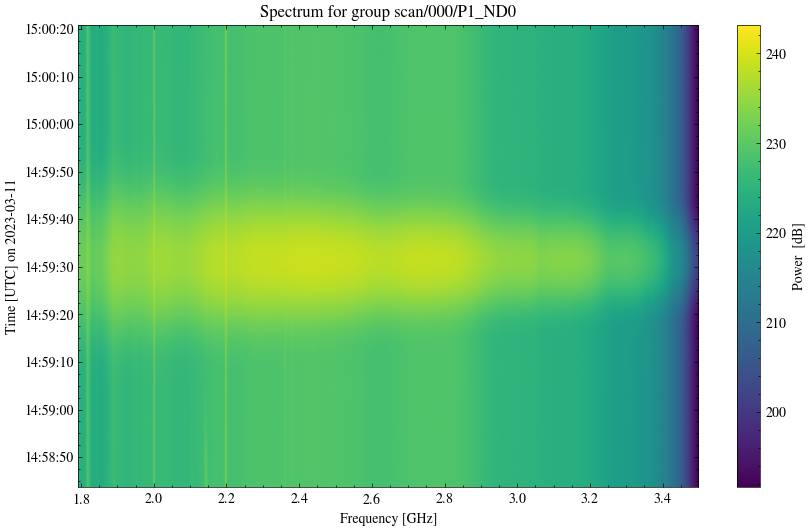

In [6]:
# define the variablues

for i,g in enumerate(datasets):
    spectrum = (10*np.log10(datasets[i]['spectrum']**2)).values[0, :,:]
    time = datasets[i]['time'].values
    frequency = datasets[i]['frequency'].values

    # Date
    time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)
    date =  pd.to_datetime(time_utc[0].strftime('%Y-%m-%d'))
    plt.figure(figsize=(10, 6))

    plt.imshow(spectrum, aspect='auto', 
    extent=[frequency[0], frequency[-1], time_utc[0], time_utc[-1]],
    origin='lower', cmap='viridis')

    plt.colorbar(label='Power  [dB]')
    plt.ylabel(f'Time [UTC] on {time_utc[0].strftime("%Y-%m-%d")}')
    plt.xlabel('Frequency [GHz]')
    plt.title(f'Spectrum for group {datasets[i].group.values[0]}')
    plt.show()

    break

In [7]:
spectrum.shape

(634, 63877)

Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz


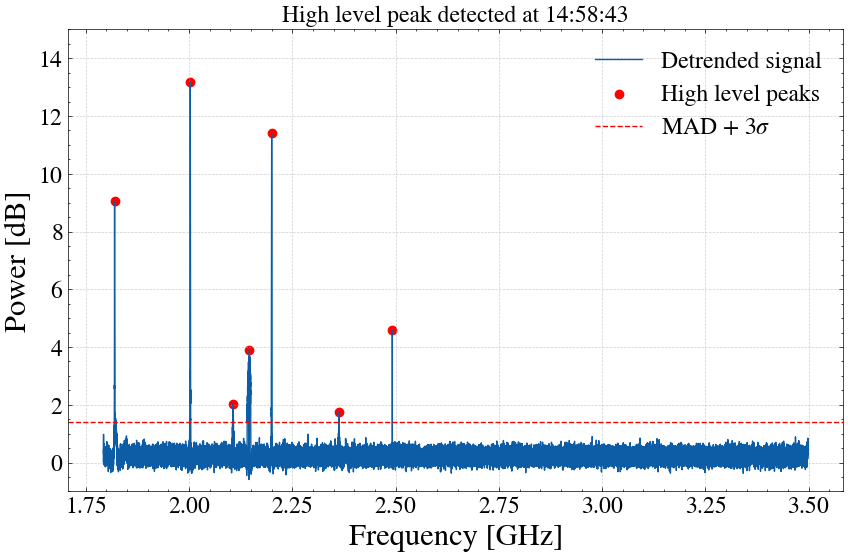

In [8]:

# Define your desired time step in seconds
time_step = 15  

# Select time indices with approximately 30-second spacing
target_times = pd.date_range(start=time_utc[0], end=time_utc[-1], freq=f'{time_step}s')

# Find nearest indices in your actual time_utc
itime_target = time_utc.get_indexer(target_times, method='nearest')


high_peaks = []
for i in itime_target:
    # Detrend / baseline correct the spectrum at this time
    det_spec_itime = base_correction(frequency, spectrum[i, :])


    sigma_value_high = 3
    # Detect peaks
    threshold = MAD(det_spec_itime) + sigma_value_high * np.std(det_spec_itime)
    peaks, properties = find_peaks(det_spec_itime,
                                   height=threshold,
                                   prominence=1.5,
                                   distance=100
                                   )

    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, det_spec_itime, label=f'Detrended signal')
    plt.scatter(frequency[peaks], det_spec_itime[peaks], color='red', label='High level peaks')
    plt.axhline(y=threshold, color='red', linestyle='--', label=f'MAD + {sigma_value_high}$σ$')

    plt.title(f'High level peak detected at {time_utc[i].strftime("%H:%M:%S")}', fontsize=17)
    plt.xlabel('Frequency [GHz]',fontsize=22)
    plt.ylabel('Power [dB]',fontsize=22)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.legend(fontsize=17)
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)
    plt.ylim(-1,15)



    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]

    print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    for peak in peaks:
        high_peaks.append({
            "Time_UTC": time_utc[i].strftime("%Y-%m-%d %H:%M:%S"),
            "Frequency_GHz": frequency[peak],
            "Power_dB": det_spec_itime[peak],
            "Threshold": threshold
        })

    plt.savefig(f"det_asls_plots/High-level-peak_{time_utc[i].strftime('%H%M%S')}.pdf", dpi=120, bbox_inches='tight')
    plt.savefig(f"det_asls_plots/High-level-peak_{time_utc[i].strftime('%H%M%S')}.png", dpi=120, bbox_inches='tight')

    
    break

In [9]:
!pwd

/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending


In [10]:
# Convert to dataframe
df_peaks = pd.DataFrame(high_peaks)

# Save CSV
df_peaks.to_csv(
    f"High_low_RFI_data/High_level_RFI_peaks_{filename.split('.')[0]}.csv",
    index=False
)

df_peaks.head()

,Time_UTC,Frequency_GHz,Power_dB,Threshold
0,2023-03-11 14:58:43,1.819628,9.049789,1.417805
1,2023-03-11 14:58:43,2.002810,13.180786,1.417805
2,2023-03-11 14:58:43,2.106337,2.032089,1.417805
3,2023-03-11 14:58:43,2.145857,3.899597,1.417805
4,2023-03-11 14:58:43,2.199903,11.399185,1.417805


Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz
Peaks detected at [14:58:58]: ['1.8196', '2.0028', '2.1416', '2.1841', '2.2000', '2.3629', '2.4920'] GHz
Peaks detected at [14:59:13]: ['1.8196', '2.0028', '2.1839', '2.2000', '2.3628', '2.4920'] GHz
Peaks detected at [14:59:28]: ['1.8196', '2.0028', '2.1999', '2.4920'] GHz
Peaks detected at [14:59:43]: ['1.8197', '2.0028', '2.1707', '2.1999', '2.3628', '2.4920'] GHz
Peaks detected at [14:59:58]: ['1.8196', '2.0028', '2.1061', '2.1841', '2.1999', '2.3628', '2.4920'] GHz
Peaks detected at [15:00:13]: ['1.8196', '2.0028', '2.1845', '2.1999', '2.3626', '2.4920'] GHz


/tmp/ipykernel_2045470/2513655501.py:44: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(name)


det_asls_plots/peak_145843.png (666, 1015, 4)
det_asls_plots/peak_145858.png (666, 1015, 4)
det_asls_plots/peak_145913.png (666, 1015, 4)
det_asls_plots/peak_145928.png (666, 1015, 4)
det_asls_plots/peak_145943.png (666, 1015, 4)
det_asls_plots/peak_145958.png (666, 1015, 4)
det_asls_plots/peak_150013.png (666, 1015, 4)


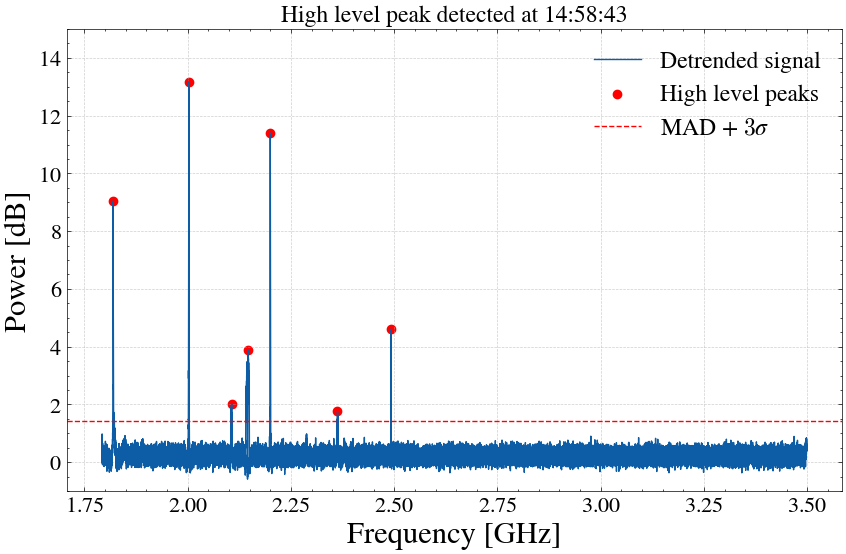

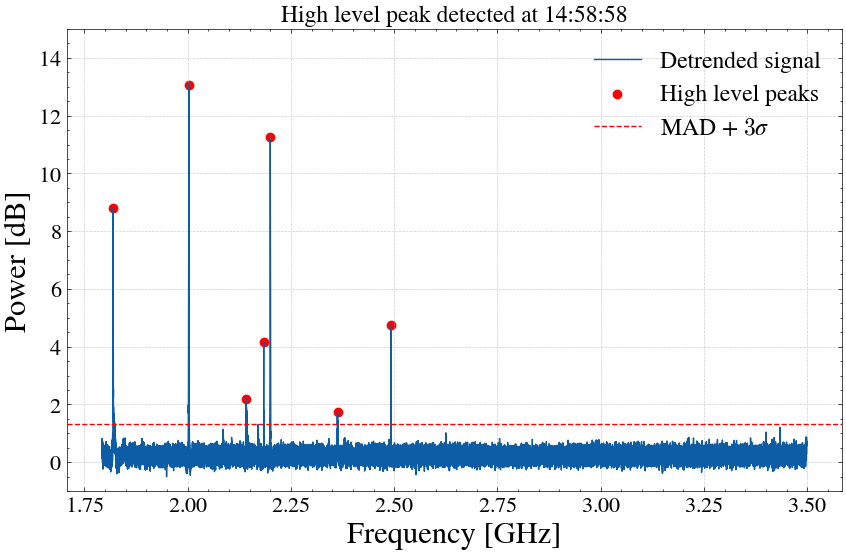

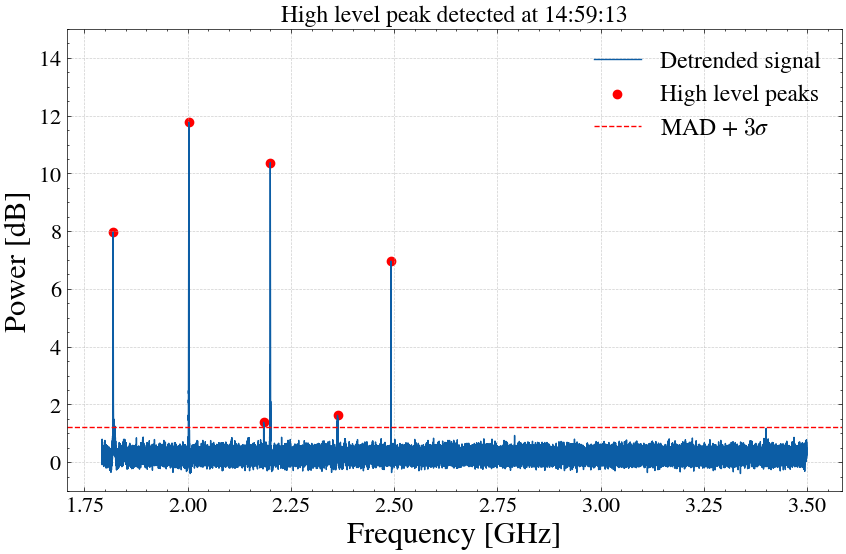

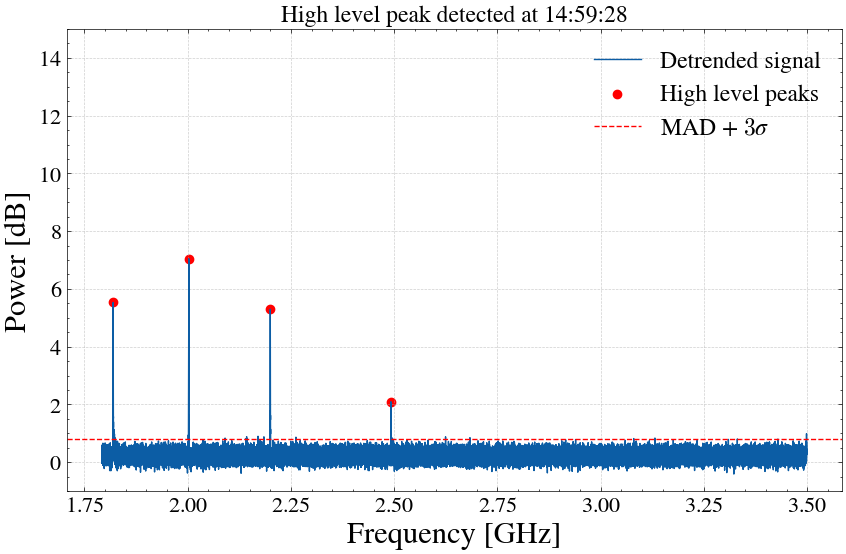

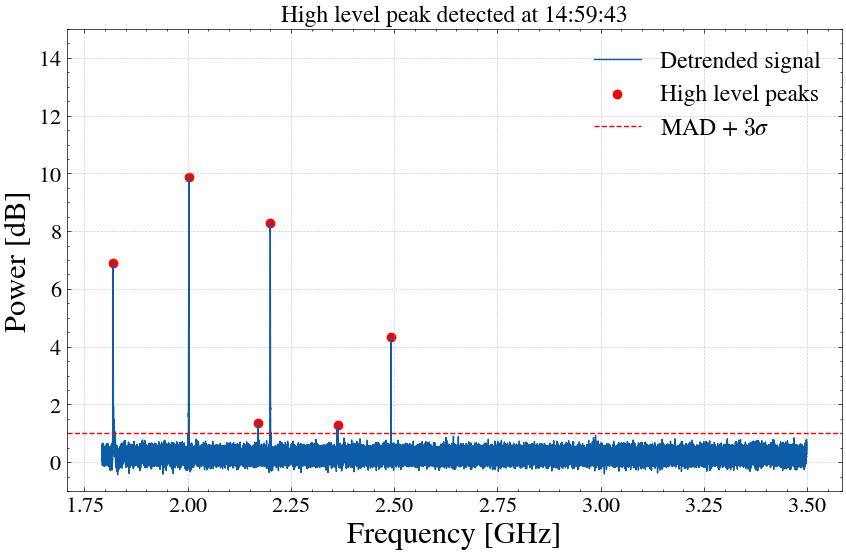

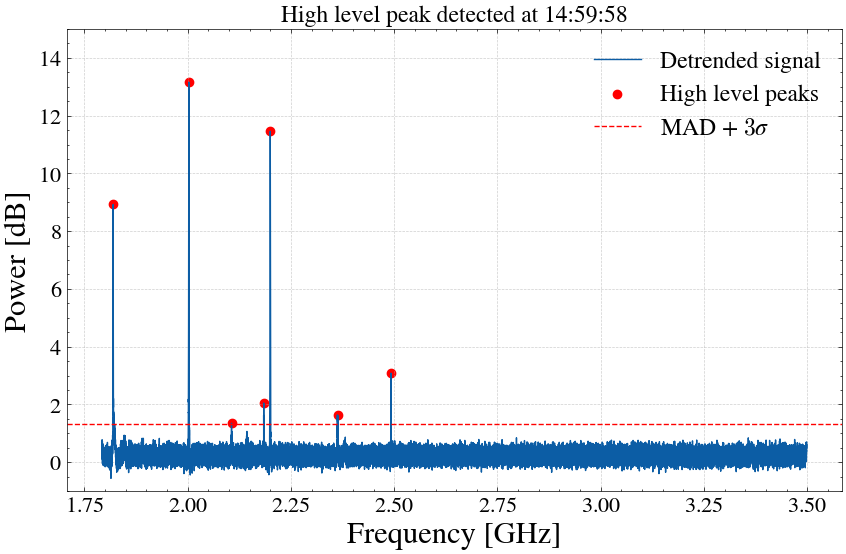

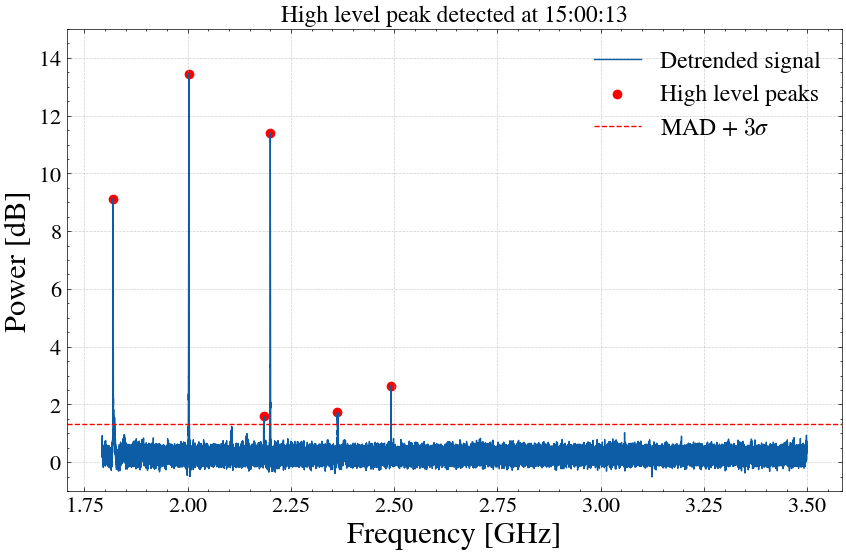

In [11]:
# save the plots as  gif animation
filenames = []
for i in itime_target:
    # Detrend / baseline correct the spectrum at this time
    det_spec_itime = base_correction(frequency, spectrum[i, :])


    # Detect peaks
    threshold = MAD(det_spec_itime) + 3 * np.std(det_spec_itime)
    peaks, properties = find_peaks(det_spec_itime,
                                   height=threshold,
                                   prominence=1.5,
                                   distance=100
                                   )

    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, det_spec_itime, label=f'Detrended signal')
    plt.scatter(frequency[peaks], det_spec_itime[peaks], color='red', label='High level peaks')
    plt.axhline(y=threshold, color='red', linestyle='--', label='MAD + $3σ$')

    plt.title(f'High level peak detected at {time_utc[i].strftime("%H:%M:%S")}', fontsize=17)
    plt.xlabel('Frequency [GHz]',fontsize=22)
    plt.ylabel('Power [dB]',fontsize=22)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)
    plt.legend(fontsize=17)

    plt.ylim(-1, 15)



    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]

    print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    name = f"det_asls_plots/peak_{time_utc[i].strftime('%H%M%S')}.png"    
    filenames.append(name)
    plt.savefig(name, dpi=120, bbox_inches='tight')

for name in filenames:
    img = imageio.imread(name)
    print(name, img.shape)


# # Clean up PNG files
# for filename in filenames:
#     os.remove(filename)

# print("GIF saved successfully!")

In [12]:
# Create GIF from saved PNGs
images = [imageio.imread(name) for name in filenames]
images = []

# Force all images to same size
base_img = Image.open(filenames[0])
base_size = base_img.size  # (width, height)

for name in filenames:
    img = Image.open(name).convert("RGB")
    img = img.resize(base_size)   # <-- force identical size
    images.append(np.array(img))

imageio.mimsave(
    f'det_asls_plots/high_level_multiple_plots_{time_utc[0].strftime("%Y-%m-%d")}.gif',
    images,
    duration=9,
    loop=0
)

/tmp/ipykernel_2045470/326657370.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(name) for name in filenames]


In [13]:
!pwd

/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending


In [14]:

frames = []

all_det = []

for i in itime_target:
    det = base_correction(frequency, spectrum[i, :])
    all_det.append(det)

all_det = np.array(all_det)

global_min = np.min(all_det)
global_max = np.max(all_det)

for i in itime_target:

    det_spec_itime = base_correction(frequency, spectrum[i, :])

    threshold = MAD(det_spec_itime) + 3 * np.std(det_spec_itime)
    peaks, _ = find_peaks(det_spec_itime, height=threshold)

    fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

    ax.plot(frequency, det_spec_itime, label=f'Detrended signal')
    ax.scatter(frequency[peaks], det_spec_itime[peaks], color='red', label='High level peaks')
    ax.axhline(y=threshold, color='red', linestyle='--', label='Mean + $3σ$')

    ax.set_xlim(frequency.min(), frequency.max())
    ax.set_ylim(global_min, global_max)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_title(f'High level peak detected at {time_utc[i].strftime("%H:%M:%S")}', fontsize=16)
    ax.set_xlabel('Frequency [GHz]',fontsize=16)
    ax.set_ylabel('Power [dB]',fontsize=16)
    ax.legend(fontsize=12)

    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=120)
    plt.close(fig)

    buf.seek(0)
    img = Image.open(buf).convert("RGB")
    frames.append(np.array(img))


imageio.mimsave(
    f'det_asls_plots/rfi_peaks_{time_utc[0].strftime("%Y-%m-%d")}.gif',
    frames,
    duration=5.0
)



Peak Analysis:

Peak 1
  Peak frequency      : 1.8188 GHz
  Left intersection   : 1.8188 GHz
  Right intersection  : 1.8189 GHz
  FWHM (bandwidth)    : 0.0001 GHz
  Corrupted channels  : 2


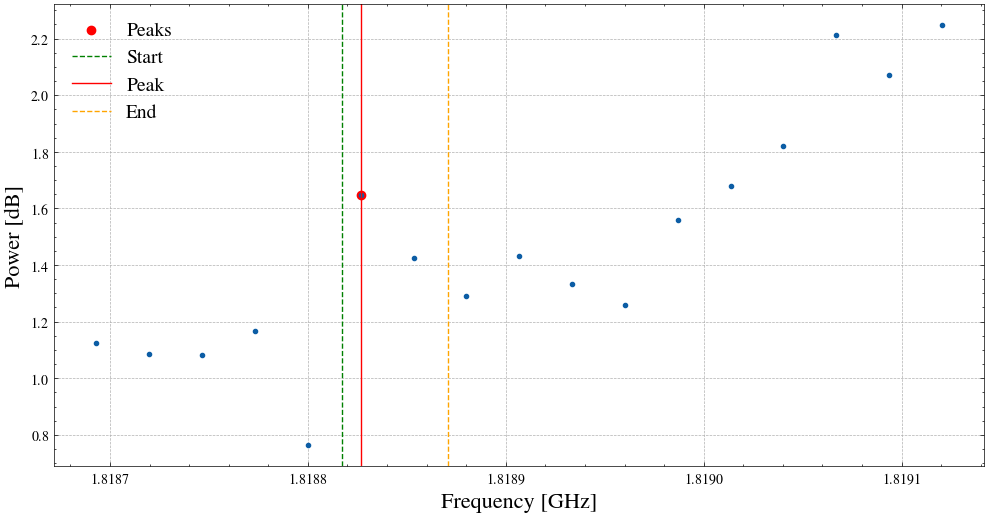

In [15]:
# peaks widths
widths, width_heights, left_ips, right_ips = peak_widths(
    det_spec_itime, peaks, rel_height=0.8
)


# spectral resolution
spectral_resolution = frequency[1] - frequency[0] # GHz per channel


# convert the indenx position to frequencies
left_rise = np.interp(left_ips, np.arange(len(frequency)), frequency)
right_set = np.interp(right_ips, np.arange(len(frequency)), frequency)


# --- Convert widths → GHz ---
width_freqs = widths * spectral_resolution

# --- Convert widths → number of channels ---
width_channels = np.round(widths).astype(int)

# --- Print results per peak ---
print("\nPeak Analysis:\n")

for k in range(len(peaks)):
    print(f"Peak {k+1}")
    print(f"  Peak frequency      : {frequency[peaks[k]]:.4f} GHz")
    print(f"  Left intersection   : {left_rise[k]:.4f} GHz")
    print(f"  Right intersection  : {right_set[k]:.4f} GHz")
    print(f"  FWHM (bandwidth)    : {width_freqs[k]:.4f} GHz")
    print(f"  Corrupted channels  : {width_channels[k]}")

    freq_range = (frequency >= (left_rise[k] - 5*spectral_resolution )) & (frequency <= (right_set[k] + 10*spectral_resolution))



    plt.figure(figsize=(12,6))
    plt.plot(frequency[freq_range], det_spec_itime[freq_range], '.')
    plt.scatter(frequency[peaks[k]], det_spec_itime[peaks[k]], color='red', label='Peaks')
    plt.axvline(left_rise[k], color='green', linestyle='--', label='Start')
    plt.axvline(frequency[peaks[k]], color='red', linestyle='-', label='Peak')
    plt.axvline(right_set[k], color='orange', linestyle='--', label='End')
    plt.xlabel('Frequency [GHz]', fontsize=16)
    plt.ylabel('Power [dB]', fontsize=16)
    plt.legend(fontsize=14)
    plt.grid(linestyle='--')

    plt.show()

    break

# Analysing each band correpted 

In [16]:
# Define a function to quantify the RFI width
def quantify_RFI_width(freq, power):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters:
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    mask : boolean array
        Mask to select the frequency window of interest.

    Returns:
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """


    # --- 1) Find where power rises above zero ---
    threshold = 0.05  # small threshold 
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- 2) Find the frequency of the peak ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]


    print(f"Start Frequency: {start_freq:.4f} GHz")
    print(f"End Frequency: {end_freq:.4f} GHz")
    print(f"Peak Frequency: {peak_freq:.4f} GHz with Power: {peak_power:.4f} dB")


    # Number of channels corrupted.
    delta_frequency = (freq[1] - freq[0])  # spectral resolution / channel width
    chans = ((end_freq - start_freq) / delta_frequency)


    print(f'Number off corrupted channels: {chans: .1f}')


    # --- Plot results ---
    plt.figure(figsize=(12,6))
    plt.plot(freq, power, '.', color='steelblue', label='Detrended signal')
    plt.axvline(start_freq, color='green', linestyle='--', label='Start', alpha=1)
    plt.axvline(peak_freq, color='red', linestyle='-', label='Peak', alpha=1)
    plt.axvline(end_freq, color='orange', linestyle='--', label='End', alpha=1)
    plt.xlabel('Frequency [GHz]', fontsize=22)
    plt.ylabel('Power [dB]', fontsize=22)
    plt.legend(fontsize=17, loc="upper right")
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)
    plt.grid(linestyle='--')

    return start_freq, end_freq, peak_freq, peak_power


Start Frequency: 1.8151 GHz
End Frequency: 1.8330 GHz
Peak Frequency: 1.8196 GHz with Power: 9.1296 dB
Number off corrupted channels:  667.0


(np.float64(1.8151416778564453),
 np.float64(1.8329524993896484),
 np.float64(1.8196277618408203),
 np.float32(9.129593))

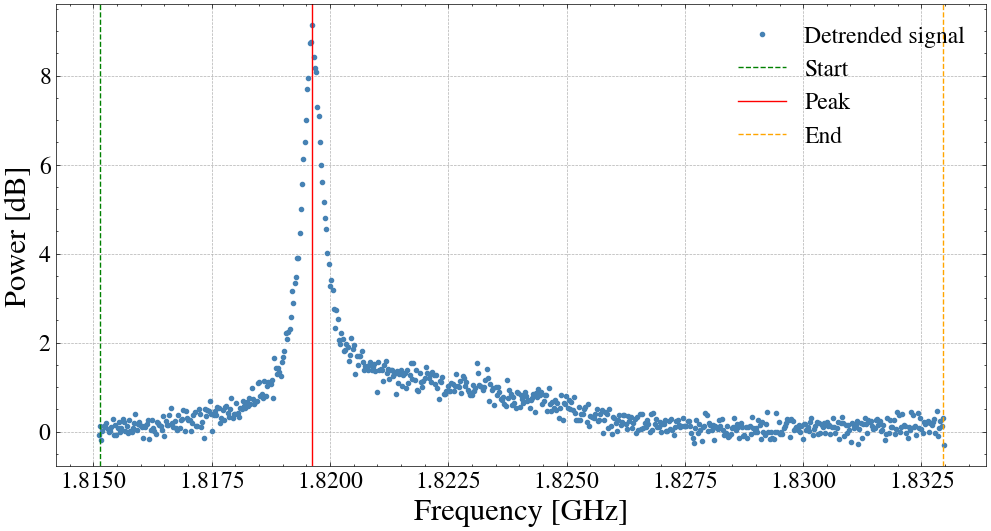

In [17]:

masker = (frequency > 1.8151) & (frequency < 1.8330)
mask = (frequency > 1.9988) & (frequency < 2.0054)
quantify_RFI_width(frequency[masker], det_spec_itime[masker])

-> As I am bining the data in time stemps, let's parallel the process to save time and be more efficient.

The Parrallel will be implement by using `concurrent.futures`. 

*ProcessPoolExecutor (True Multi-Core Parallelism)*

In [18]:
# import the library

from concurrent.futures import ProcessPoolExecutor

In [19]:
# process for a single time step

def process_single_time(i, frequency, spectrum, time_utc):
    """
    Process a single time step
    - i -> for each time step/binning
    - baseline correction
    - peak detection
    - return results
    """

    det_spec_itime = base_correction(frequency, spectrum[i, :])
    threshold = MAD(det_spec_itime) + 3 * np.std(det_spec_itime)
    peaks, properties = find_peaks(det_spec_itime,
                                   height=threshold,
                                   prominence=1.5,
                                   distance=100
                                   )
    peak_freqs = frequency[peaks]


    return {
        "time_index": i,
        "time_label": time_utc[i].strftime("%H:%M:%S"),
        "det_spec": det_spec_itime,
        "peaks": peaks,
        "peak_freqs": peak_freqs,
        "threshold": threshold
    }

# Run in parallel for all target times

def process_all_times(frequency,spectrum,time_utc, time_step, n_workers=None):
    
    target_times = pd.date_range(
        start=time_utc[0],
        end=time_utc[-1],
        freq=f'{time_step}s'
    )

    itime_target = time_utc.get_indexer(target_times, method='nearest')

    with ProcessPoolExecutor(max_workers=n_workers) as executor:

        features = [
            executor.submit(process_single_time, i, frequency, spectrum, time_utc)
            for i in itime_target
        ]
        results_sing_proc = [f.result() for f in features]


    return results_sing_proc



Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz


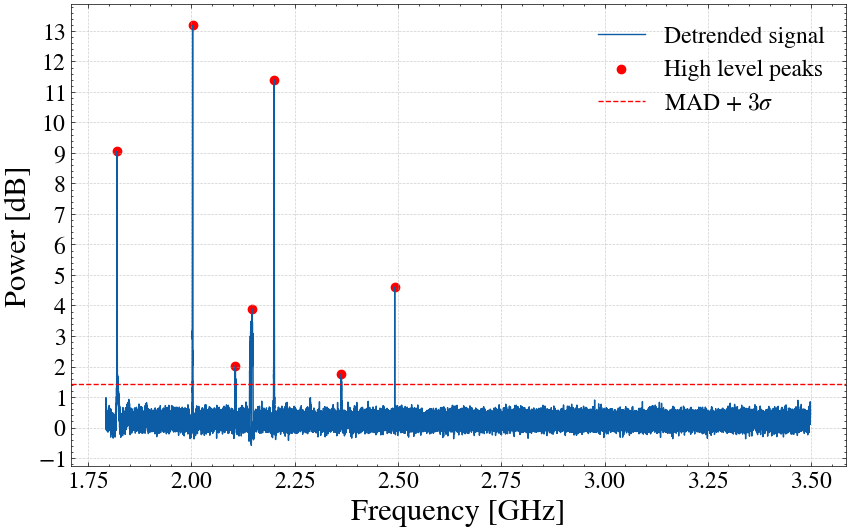

In [20]:
# run for a single time step to test
target = process_single_time(itime_target[0], frequency, spectrum, time_utc)

# --- Print detected peak frequencies ---
formatted_freqs = [f"{f:.4f}" for f in target['peak_freqs']]

print(f"Peaks detected at [{time_utc[target['time_index']].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")


plt.figure(figsize=(10, 6))
plt.plot(frequency, target['det_spec'], label=f'Detrended signal')
plt.scatter(frequency[target['peaks']], target['det_spec'][target['peaks']], color='red', label='High level peaks')
plt.axhline(y=target['threshold'], color='red', linestyle='--', label='MAD + $3σ$')
#plt.title(f'High Level Peak detected at {target["time_label"]}', fontsize=16)
plt.xlabel('Frequency [GHz]',fontsize=22)
plt.ylabel('Power [dB]',fontsize=22)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=17)

yticks=np.arange(-1, 14, 1)
plt.yticks(yticks, fontsize=17)
plt.legend(fontsize=17)
plt.xticks(fontsize=17)
plt.show()

In [21]:
# plot for all time steps
results_all_times = process_all_times(frequency, spectrum, time_utc, time_step=15)


Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz


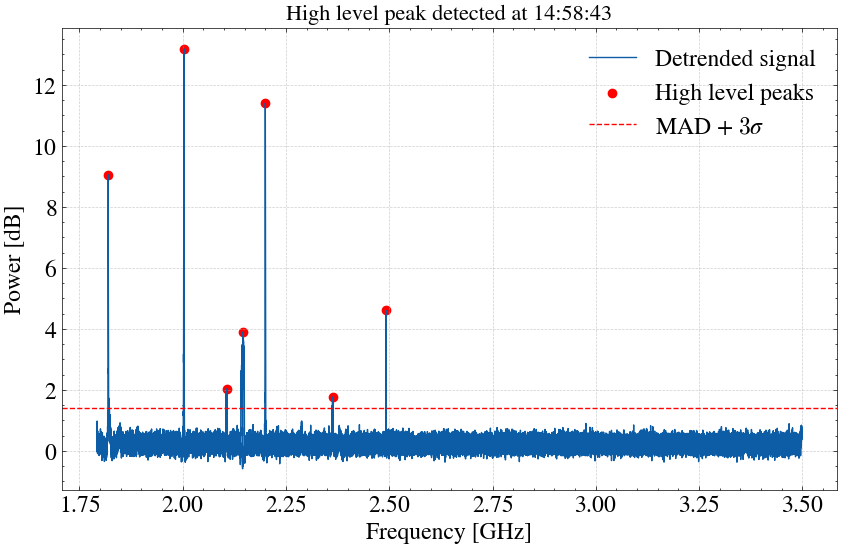

In [22]:


for res in results_all_times:

        # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in res['peak_freqs']]

    print(f"Peaks detected at [{time_utc[res['time_index']].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")


    plt.figure(figsize=(10, 6))
    plt.plot(frequency, res['det_spec'], label=f'Detrended signal')
    plt.scatter(frequency[res['peaks']], res['det_spec'][res['peaks']], color='red', label='High level peaks')
    plt.axhline(y=res['threshold'], color='red', linestyle='--', label='MAD + $3σ$')
    plt.title(f'High level peak detected at {res["time_label"]}', fontsize=16)
    plt.xlabel('Frequency [GHz]',fontsize=17)
    plt.ylabel('Power [dB]',fontsize=17)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=17)
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)

    plt.show()

    break

# Frequency-of-occurrence analysis

-> From all detected peaks across time, determine which frequencies persist throughout the observation and show their occurrence percentage.

For  each detected peak:
* collect all peak frequencies acrros time;
* bin then info frequency bins;
* count how many time each bin appears;
* convert to percentage: P[%] = $ \frac{number of detections in bin}{number of time samples} x 100 $

In [23]:
# collet all peak frequencies 
all_peak_freqs = []
n_time_samples = len(results_all_times)

for res in results_all_times:
    all_peak_freqs.append(res['peak_freqs'])


# convert to Numpy array
all_peak_freqs = np.concatenate(
    [res['peak_freqs'] for res in results_all_times]
)  

# define the frequency bins for the histogram
freq_resolution = frequency[1] - frequency[0]
freq_bins = np.arange(frequency[0], frequency[-1] + freq_resolution, freq_resolution)

# compute histogram counts
counts, bin_edges = np.histogram(all_peak_freqs, bins=freq_bins)

# converts to percentage
percentages = (counts / n_time_samples) * 100
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


In [24]:
# Define RFI bands (GHz) for MeerKAT S-band (1.75–3.5 GHz)
rfi_bands = {

"Cellular GSM Downlink": (1.71, 1.785),
"Cellular GSM Uplink": (1.805, 1.88),

"DECT Phones": (1.88, 1.90),

"UMTS Uplink": (1.92, 1.98),
"UMTS Downlink": (2.11, 2.17),

"Mobile Satellite": (2.00, 2.20),

"Space Research / EESS": (2.20, 2.29),

"IMT 2300 (4G/5G)": (2.30, 2.40),

"Wi-Fi / Bluetooth (ISM)": (2.40, 2.483),

"LTE / 5G (2600 band)": (2.50, 2.69),

"Air Traffic Radar": (2.70, 2.90),

"Weather Radar": (2.70, 3.00),

"Microwave Backhaul": (3.00, 3.30),

"5G NR (n78)": (3.30, 3.60)
}

colors = [
"#E41A1C","#377EB8","#4DAF4A","#984EA3","#FF7F00",
"#FFFF33","#A65628","#F781BF","#999999","#66C2A5",
"#FC8D62","#8DA0CB","#E78AC3","#A6D854"
]


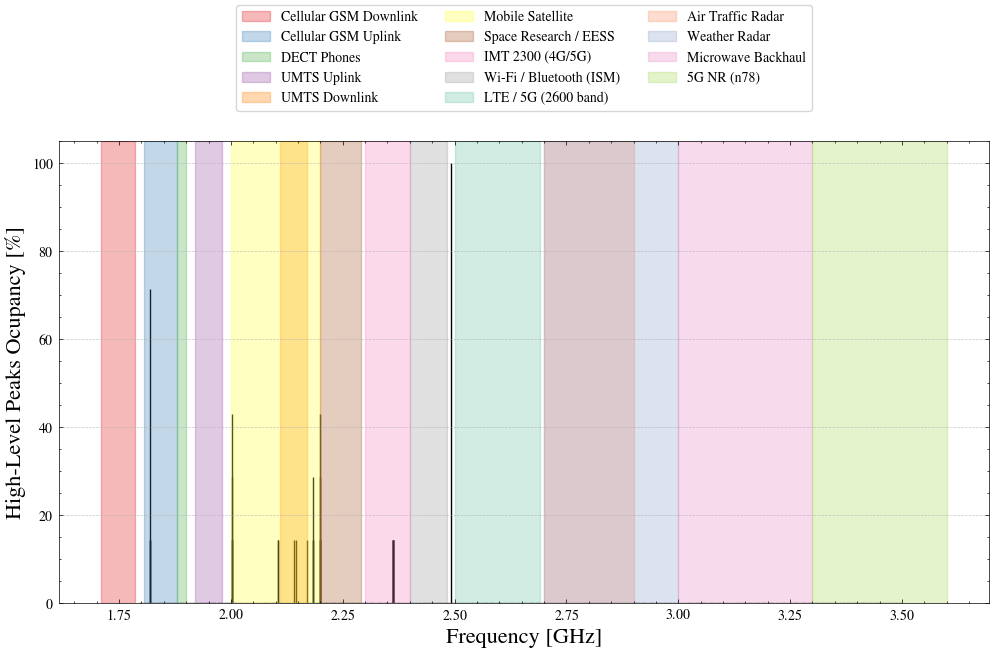

In [25]:

# # Define RFI bands (GHz) for MeerKAT S-band (1.75–3.5 GHz)
# rfi_bands = {
    
#     "GSM Uplink": (1.805, 1.88),
#     "Mobile Sat. Uplink": (2.00, 2.02),
#     "3G/UMTS Uplink": (2.10, 2.20),   # Universal Mobile Telecommunications System
#     "Satellite Downlink": (2.20, 2.30),
#     "Earth Exploration Sat.": (2.32, 2.36),
#     "Wi-Fi / ISM": (2.40, 2.50),   # Industrial, Scientific, and Medical band 
# }

# colors = [
#     "#AFA5A5", "#f1060661", "#67498361", "#1196f684","#e36f098b","#1CC21C79",
# ]

# plot the histogram of peak frequencies
plt.figure(figsize=(12, 6))
plt.bar(bin_centers, percentages, width=freq_resolution*0.8, align='center', edgecolor='black')

# --- Overlay RFI bands ---
for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
    plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('High-Level Peaks Ocupancy [%]', fontsize=16)
#plt.title('Distribution of Detected RFI Peak Frequencies', fontsize=18)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(
    bbox_to_anchor=(0.5, 1.05),
    loc='lower center',
    ncol=3,                
    fontsize=10,
    frameon=True
)


#plt.savefig(f'percentage_detected_HL_peaks{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=120, bbox_inches='tight')



In [26]:
occupancy = np.zeros(len(frequency))

for res in results_all_times:
    occupancy[res["peaks"]] += 1

percentage = (occupancy / n_time_samples) * 100

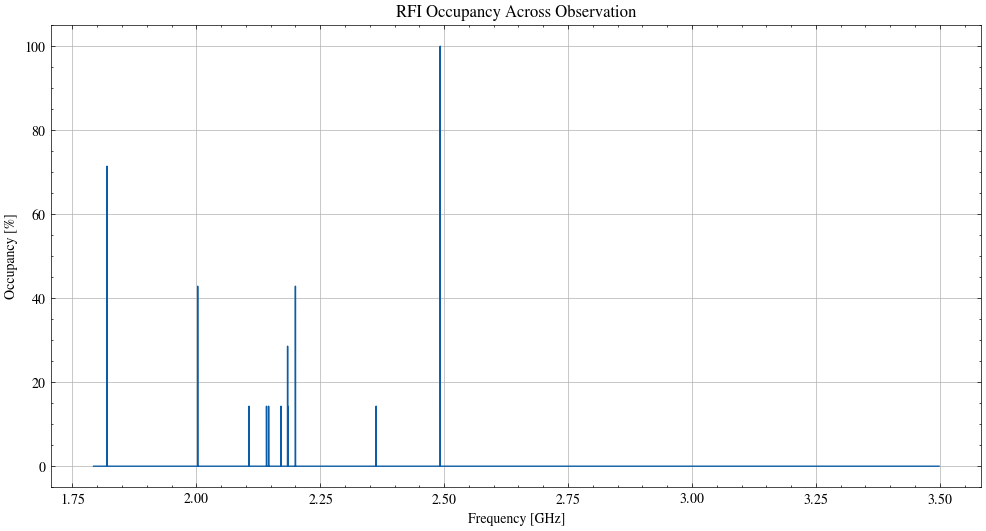

In [27]:
plt.figure(figsize=(12,6))
plt.plot(frequency, percentage)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Occupancy [%]")
plt.title("RFI Occupancy Across Observation")
plt.grid(True)
plt.show()

## Occupancy percentage per frequency channel

Identify only frequencies where peaks occurred

Print the frequency

Print its percentage over the full observation

In [28]:
# extract olny frequencies where peaks occured
peak_channels = np.where(occupancy > 0)[0]
print("Detected Peaks Across Full Observation:\n")

for ch in peak_channels:
    print(f"Frequency: {frequency[ch]:.6f} GHz  |  "
          f"Occurrence: {percentage[ch]:.2f} %")

Detected Peaks Across Full Observation:

Frequency: 1.819601 GHz  |  Occurrence: 14.29 %
Frequency: 1.819628 GHz  |  Occurrence: 71.43 %
Frequency: 1.819654 GHz  |  Occurrence: 14.29 %
Frequency: 2.002756 GHz  |  Occurrence: 42.86 %
Frequency: 2.002783 GHz  |  Occurrence: 28.57 %
Frequency: 2.002810 GHz  |  Occurrence: 14.29 %
Frequency: 2.002836 GHz  |  Occurrence: 14.29 %
Frequency: 2.106150 GHz  |  Occurrence: 14.29 %
Frequency: 2.106337 GHz  |  Occurrence: 14.29 %
Frequency: 2.141611 GHz  |  Occurrence: 14.29 %
Frequency: 2.145857 GHz  |  Occurrence: 14.29 %
Frequency: 2.170744 GHz  |  Occurrence: 14.29 %
Frequency: 2.183935 GHz  |  Occurrence: 14.29 %
Frequency: 2.184149 GHz  |  Occurrence: 28.57 %
Frequency: 2.184549 GHz  |  Occurrence: 14.29 %
Frequency: 2.199903 GHz  |  Occurrence: 28.57 %
Frequency: 2.199930 GHz  |  Occurrence: 42.86 %
Frequency: 2.199957 GHz  |  Occurrence: 14.29 %
Frequency: 2.199984 GHz  |  Occurrence: 14.29 %
Frequency: 2.362631 GHz  |  Occurrence: 14.29 %

In [29]:
# Sorte by higest Persistence

sorted_indices = peak_channels[np.argsort(percentage[peak_channels])[::-1]]

print("Persistent RFI Frequencies (sorted by occurrence):\n")

for ch in sorted_indices:
    print(f"{frequency[ch]:.6f} GHz  -->  {percentage[ch]:.2f} %")

Persistent RFI Frequencies (sorted by occurrence):

2.492006 GHz  -->  100.00 %
1.819628 GHz  -->  71.43 %
2.002756 GHz  -->  42.86 %
2.199930 GHz  -->  42.86 %
2.184149 GHz  -->  28.57 %
2.199903 GHz  -->  28.57 %
2.002783 GHz  -->  28.57 %
2.362898 GHz  -->  14.29 %
2.362764 GHz  -->  14.29 %
2.362818 GHz  -->  14.29 %
2.199957 GHz  -->  14.29 %
2.199984 GHz  -->  14.29 %
2.362631 GHz  -->  14.29 %
2.362711 GHz  -->  14.29 %
2.362791 GHz  -->  14.29 %
2.170744 GHz  -->  14.29 %
2.184549 GHz  -->  14.29 %
2.183935 GHz  -->  14.29 %
2.106337 GHz  -->  14.29 %
2.141611 GHz  -->  14.29 %
2.145857 GHz  -->  14.29 %
2.106150 GHz  -->  14.29 %
2.002810 GHz  -->  14.29 %
2.002836 GHz  -->  14.29 %
1.819654 GHz  -->  14.29 %
1.819601 GHz  -->  14.29 %


# Flag the high level outlier from the data

For each detected peak frequency:

1. Find the closest index in the frequency array

2. From that index:

    * Walk LEFT until power drops below threshold

    * Walk RIGHT until power drops below threshold

3. Store:

    * start_freq

    * peak_freq

    * end_freq

4. Plot only that local region. This ensures:

    * Each peak is treated independently

    * No need for mask window

    * Works even when peaks are close together

In [30]:

def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum at ONE time step.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(8,4))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=16)
            plt.ylabel("Detrended Power [dB]", fontsize=16)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(alpha=0.3)
            plt.legend(fontsize=12, )
            plt.show()


    return results_outliers


Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 8.7508 dB
  Start Frequency: 1.8175 GHz
  End Frequency  : 1.8258 GHz
  Bandwidth      : 0.0083 GHz
  Corrupted Ch.  : 309 channels


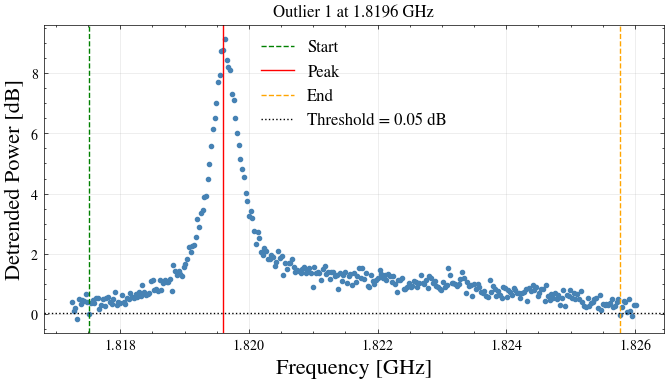


Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 12.9994 dB
  Start Frequency: 2.0007 GHz
  End Frequency  : 2.0051 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 164 channels


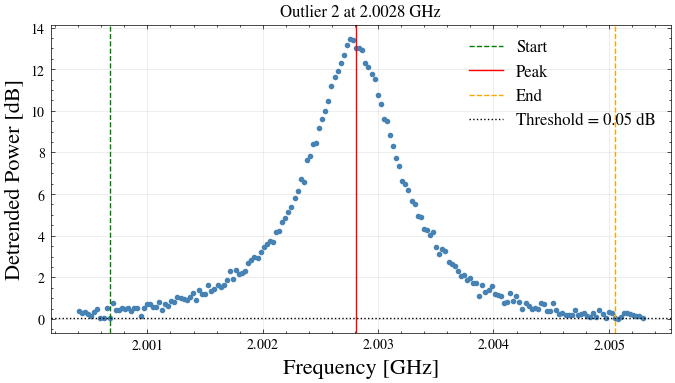


Outlier 3:
  Peak Frequency : 2.1063 GHz
  Peak Power     : 0.6897 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


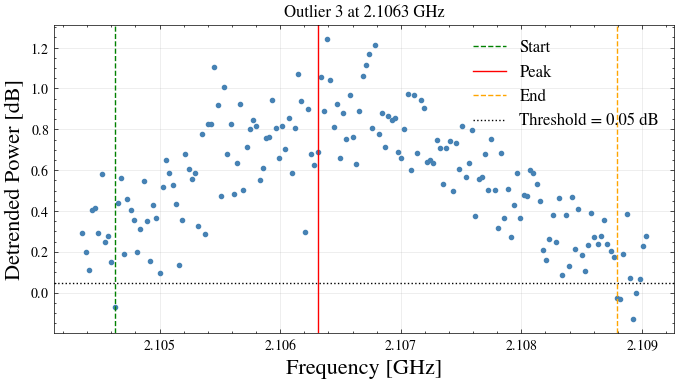


Outlier 4:
  Peak Frequency : 2.1459 GHz
  Peak Power     : 0.1821 dB
  Start Frequency: 2.1452 GHz
  End Frequency  : 2.1475 GHz
  Bandwidth      : 0.0023 GHz
  Corrupted Ch.  : 85 channels


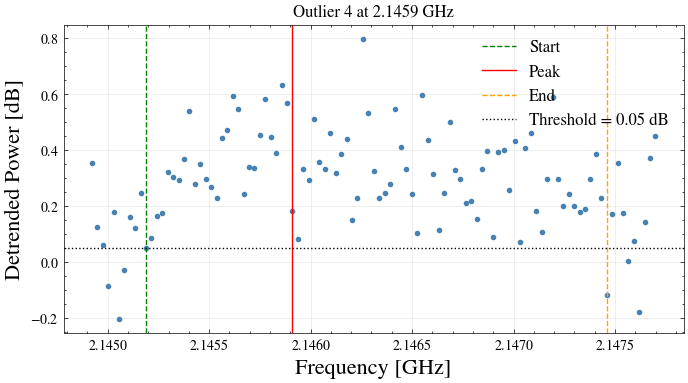


Outlier 5:
  Peak Frequency : 2.1999 GHz
  Peak Power     : 11.3218 dB
  Start Frequency: 2.1978 GHz
  End Frequency  : 2.2022 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 163 channels


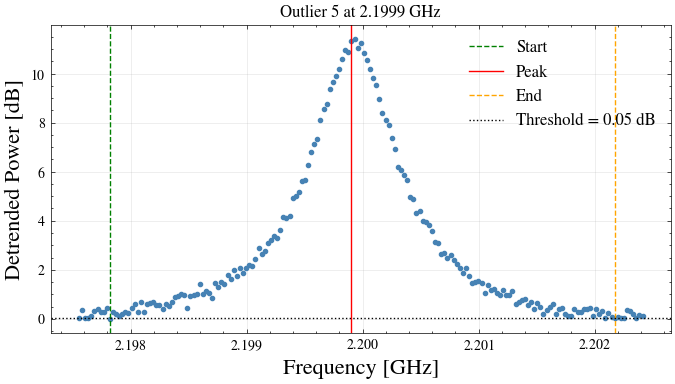


Outlier 6:
  Peak Frequency : 2.3627 GHz
  Peak Power     : 1.5163 dB
  Start Frequency: 2.3607 GHz
  End Frequency  : 2.3651 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 165 channels


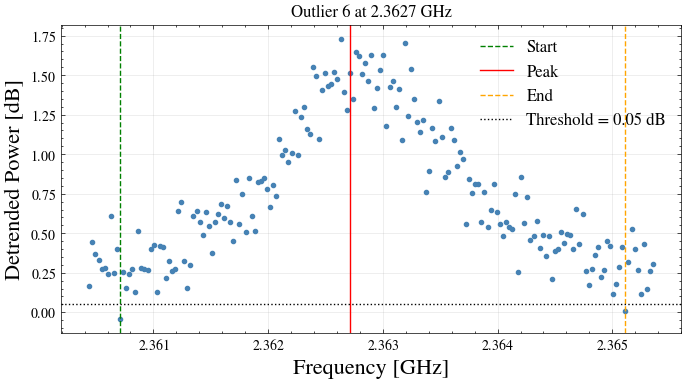


Outlier 7:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 2.6454 dB
  Start Frequency: 2.4914 GHz
  End Frequency  : 2.4930 GHz
  Bandwidth      : 0.0017 GHz
  Corrupted Ch.  : 62 channels


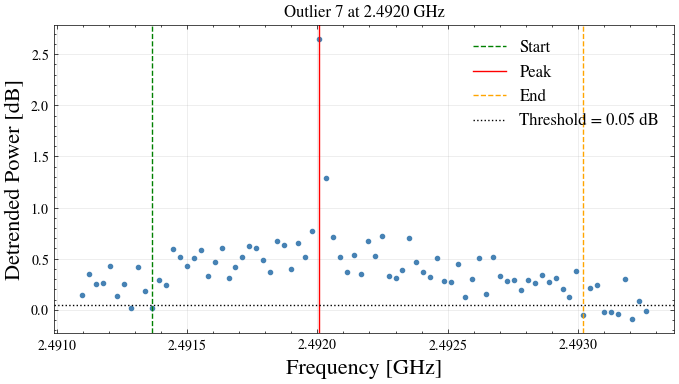

[{'peak_freq': np.float64(1.819601058959961),
  'peak_power': np.float32(8.750809),
  'start_freq': np.float64(1.8175182342529297),
  'end_freq': np.float64(1.8257694244384766),
  'bandwidth': np.float64(0.008251190185546875),
  'n_channels': 309},
 {'peak_freq': np.float64(2.002809524536133),
  'peak_power': np.float32(12.999359),
  'start_freq': np.float64(2.000673294067383),
  'end_freq': np.float64(2.0050525665283203),
  'bandwidth': np.float64(0.0043792724609375),
  'n_channels': 164},
 {'peak_freq': np.float64(2.1063098907470703),
  'peak_power': np.float32(0.6896515),
  'start_freq': np.float64(2.1046276092529297),
  'end_freq': np.float64(2.108793258666992),
  'bandwidth': np.float64(0.0041656494140625),
  'n_channels': 156},
 {'peak_freq': np.float64(2.1459102630615234),
  'peak_power': np.float32(0.1821289),
  'start_freq': np.float64(2.1451892852783203),
  'end_freq': np.float64(2.147459030151367),
  'bandwidth': np.float64(0.002269744873046875),
  'n_channels': 85},
 {'peak

In [31]:
peak_list = [1.8196, 2.0028, 2.1063, 
             2.1459, 2.1999, 2.3627, 2.4920]

quantify_all_outliers(frequency, det_spec_itime, peak_list)

Process for each time stemp

In [32]:

for res in results_all_times:

        # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in res['peak_freqs']]

    print(f"\nPeaks detected at [{time_utc[res['time_index']].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    rest = res['det_spec']

    results_outliers = quantify_all_outliers(frequency, rest, res['peak_freqs'], plot=False)


Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 9.0498 dB
  Start Frequency: 1.8170 GHz
  End Frequency  : 1.8260 GHz
  Bandwidth      : 0.0090 GHz
  Corrupted Ch.  : 338 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 13.1808 dB
  Start Frequency: 2.0008 GHz
  End Frequency  : 2.0048 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels

Outlier 3:
  Peak Frequency : 2.1063 GHz
  Peak Power     : 2.0321 dB
  Start Frequency: 2.1043 GHz
  End Frequency  : 2.1084 GHz
  Bandwidth      : 0.0041 GHz
  Corrupted Ch.  : 153 channels

Outlier 4:
  Peak Frequency : 2.1459 GHz
  Peak Power     : 3.8996 dB
  Start Frequency: 2.1452 GHz
  End Frequency  : 2.1495 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 163 channels

Outlier 5:
  Peak Frequency : 2.1999 GHz
  Peak Power     : 11.3992 dB
  Start Frequency: 2.1980 GHz
  End Frequency  : 

In [33]:
results_outliers[0]['start_freq']

np.float64(1.8175182342529297)

In [34]:
len(results_outliers)

6

# Flag the high level RFI

For each time bin:

1. Use all detected (start_freq, end_freq) ranges

2. Flag those frequency channels in the power spectrum

3. Plot:

* Original spectrum

* Flagged spectrum (with RFI removed or masked)

This is exactly how RFI masks are constructed in radio astronomy.

In [35]:
# RFI mask

def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask

``` For the low level RFI we changed the thresholt to MAD + 5STD- because it alow us to just peak the realy prominet values. The 3*STD was peaking some information of the the actual signal variation.```

Peaks detected at [14:58:43]: ['2.1063', '2.1459', '2.1487'] GHz
Peaks detected at [14:58:58]: ['2.0859', '2.1416', '2.1703', '2.6250', '3.4003', '3.4340'] GHz
Peaks detected at [14:59:13]: ['2.7915', '3.4003'] GHz
Peaks detected at [14:59:28]: [] GHz
Peaks detected at [14:59:43]: ['2.1707', '2.9874'] GHz
Peaks detected at [14:59:58]: ['1.8459', '2.1061', '2.1434'] GHz
Peaks detected at [15:00:13]: ['1.8463', '2.1064', '2.1432', '3.0577'] GHz


/tmp/ipykernel_2045470/1630405223.py:77: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(name)


det_asls_plots/low_peak_14:58:43.png (668, 1020, 4)
det_asls_plots/low_peak_14:58:58.png (668, 1020, 4)
det_asls_plots/low_peak_14:59:13.png (668, 1020, 4)
det_asls_plots/low_peak_14:59:28.png (668, 1020, 4)
det_asls_plots/low_peak_14:59:43.png (668, 1020, 4)
det_asls_plots/low_peak_14:59:58.png (668, 1020, 4)
det_asls_plots/low_peak_15:00:13.png (667, 1020, 4)


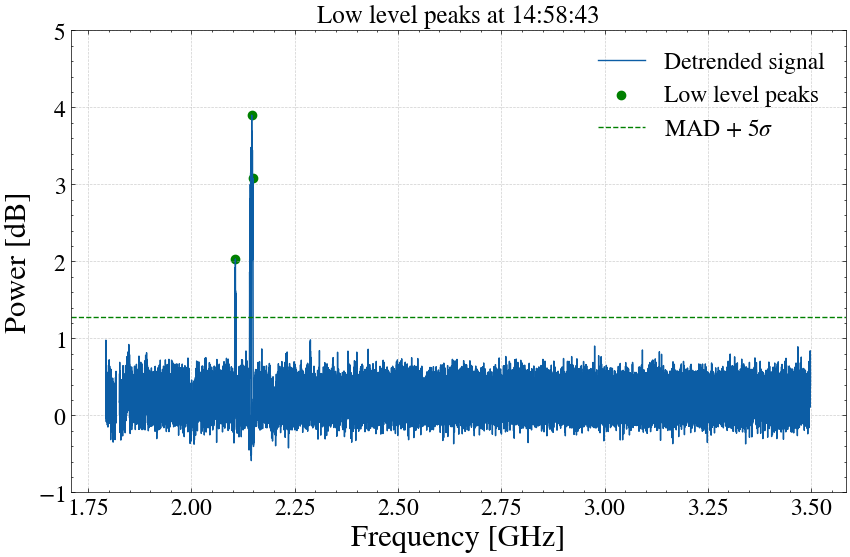

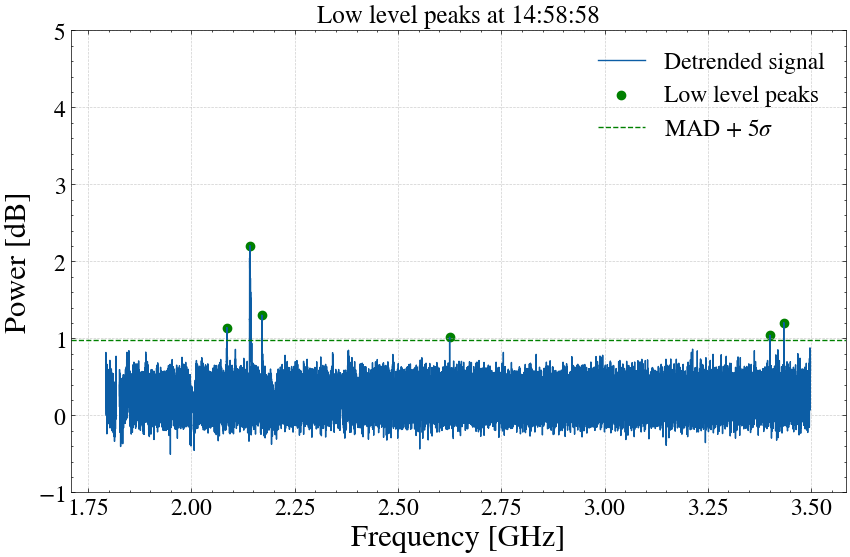

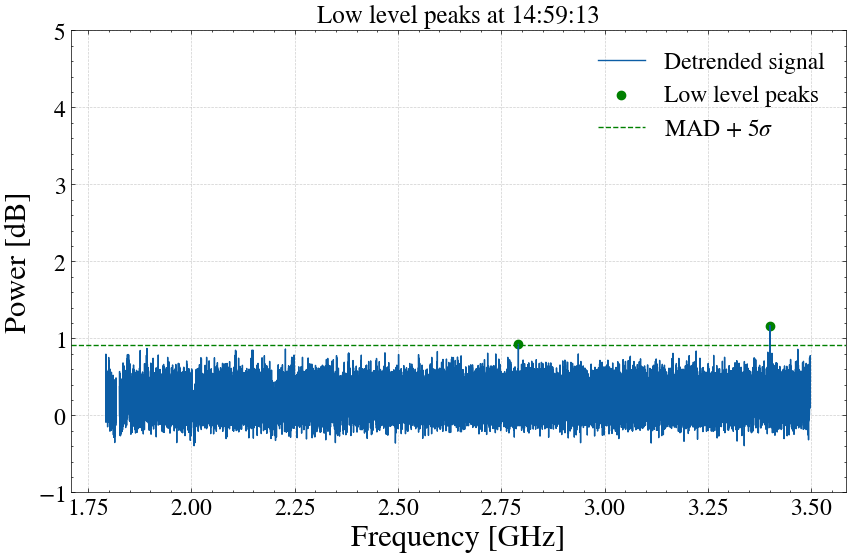

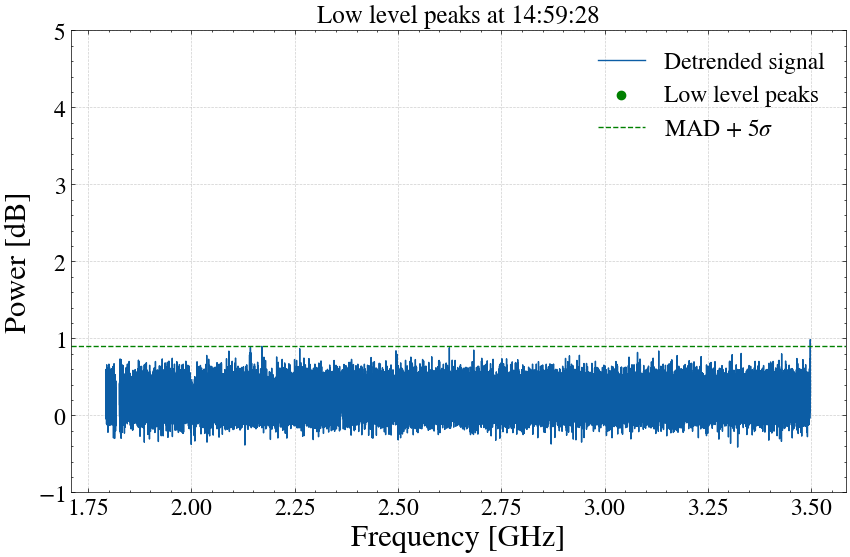

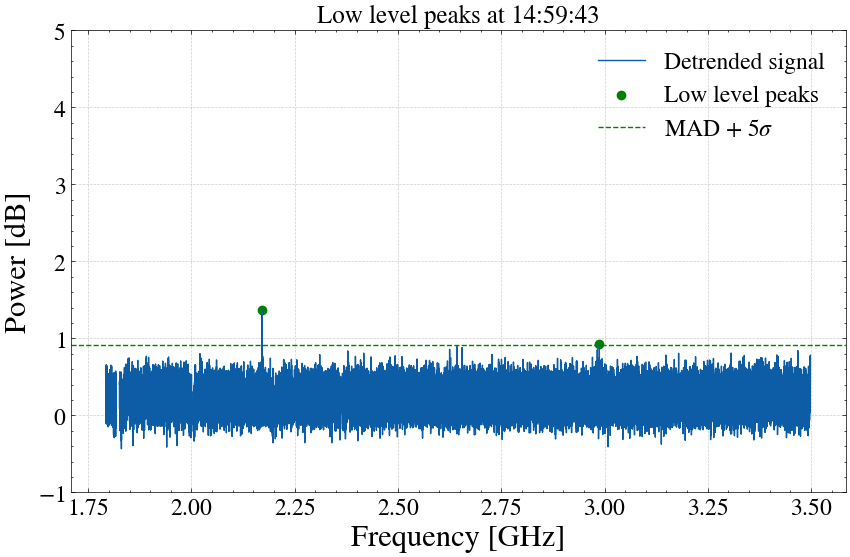

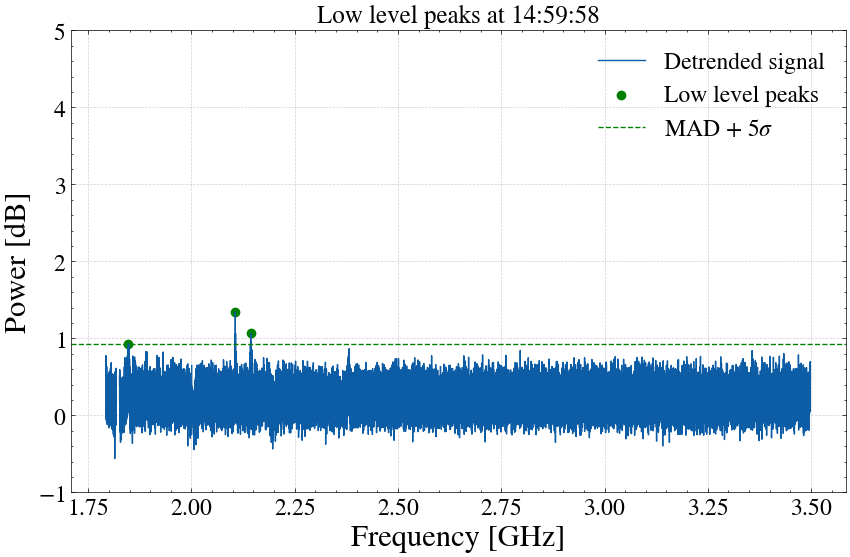

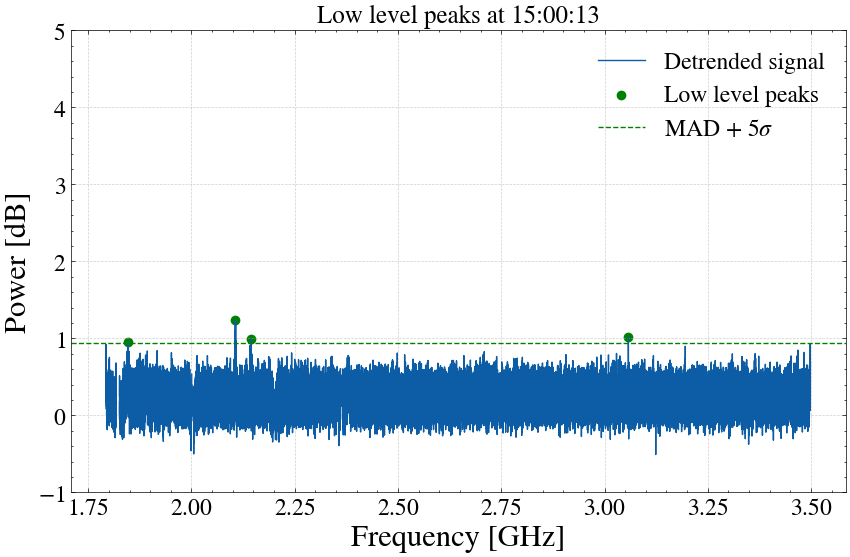

In [36]:
low_peak_results = []
filename_low = []

for i in itime_target:

    # 1) Detrend
    det_spec_itime = base_correction(frequency, spectrum[i, :])

    # 2) Build mask (must correspond to THIS time step)
    flag = build_rfi_mask(frequency, results_outliers)

    # 3) Apply mask (1D indexing!)
    spectrum_flagged = det_spec_itime.copy()
    spectrum_flagged[flag] = np.nan

    # 4) Detect peaks (ignore NaNs)
    clean_spec = np.nan_to_num(spectrum_flagged, nan=0)

    sigma_value_low = 5 
    threshold = MAD(clean_spec) + sigma_value_low * np.std(clean_spec)


    peaks_low, properties = find_peaks(
        clean_spec,
        height=threshold,
        prominence=1,
        distance=100
    )


    # 5) Save detected peak
    for peak in peaks_low:
        low_peak_results.append({
            "Time_UTC": time_utc[i].strftime("%Y-%m-%d %H:%M:%S"),
            "Frequency_GHz": frequency[peak],
            "Power_dB": clean_spec[peak],
            "Threshold": threshold
        })

    # 5) Plot
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, spectrum_flagged, label='Detrended signal')
    plt.scatter(frequency[peaks_low], clean_spec[peaks_low], 
                color='green', label='Low level peaks')

    plt.axhline(y=threshold, color='green', linestyle='--',
                label=f'MAD + {sigma_value_low}$σ$')

    plt.title(f'Low level peaks at {time_utc[i].strftime("%H:%M:%S")}', fontsize=18)
    plt.xlabel('Frequency [GHz]', fontsize=22)
    plt.ylabel('Power [dB]', fontsize=22)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=17)
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)

    plt.ylim(-1, 5)
    # #define the yticks size the same for all the plots
    # yticks=np.arange(-1, 5, )
    # plt.yticks(yticks)


    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks_low]]
    print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    


    name_low = f"det_asls_plots/low_peak_{time_utc[i].strftime('%H:%M:%S')}.png"    
    filename_low.append(name_low)
    plt.savefig(name_low, dpi=120, bbox_inches='tight')

    #plt.show()

    #break  # Remove this break to process all time steps
for name in filename_low:
    img = imageio.imread(name)
    print(name, img.shape)





Peaks detected at [14:58:43]: ['2.1063', '2.1459', '2.1487'] GHz


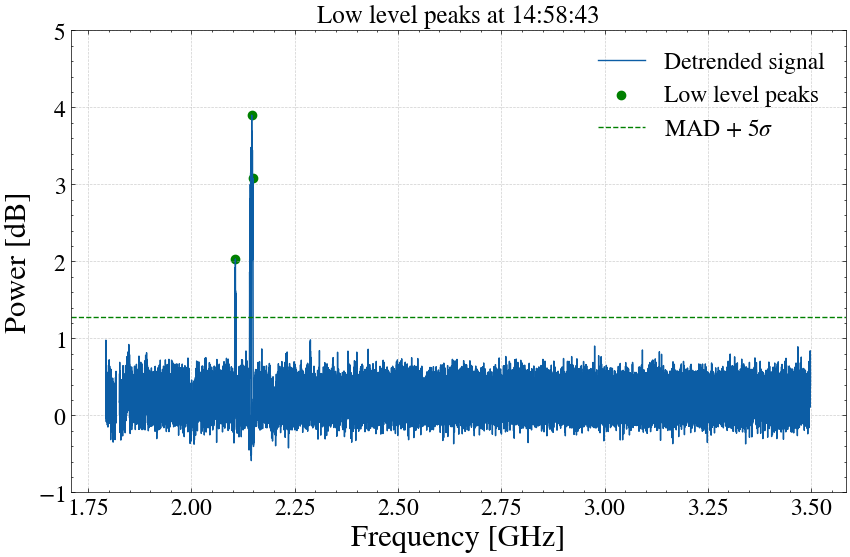

In [37]:

for i in itime_target:

    # 1) Detrend
    det_spec_itime = base_correction(frequency, spectrum[i, :])

    # 2) Build mask (must correspond to THIS time step)
    flag = build_rfi_mask(frequency, results_outliers)

    # 3) Apply mask (1D indexing!)
    spectrum_flagged = det_spec_itime.copy()
    spectrum_flagged[flag] = np.nan

    # 4) Detect peaks (ignore NaNs)
    clean_spec = np.nan_to_num(spectrum_flagged, nan=0)

    sigma_value_low = 5 
    threshold = MAD(clean_spec) + sigma_value_low * np.std(clean_spec)


    peaks_low, properties = find_peaks(
        clean_spec,
        height=threshold,
        prominence=1,
        distance=100
    )


    # 5) Save detected peak
    for peak in peaks_low:
        low_peak_results.append({
            "Time_UTC": time_utc[i].strftime("%Y-%m-%d %H:%M:%S"),
            "Frequency_GHz": frequency[peak],
            "Power_dB": clean_spec[peak],
            "Threshold": threshold
        })

    # 5) Plot
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, spectrum_flagged, label='Detrended signal')
    plt.scatter(frequency[peaks_low], clean_spec[peaks_low], 
                color='green', label='Low level peaks')

    plt.axhline(y=threshold, color='green', linestyle='--',
                label=f'MAD + {sigma_value_low}$σ$')

    plt.title(f'Low level peaks at {time_utc[i].strftime("%H:%M:%S")}', fontsize=18)
    plt.xlabel('Frequency [GHz]', fontsize=22)
    plt.ylabel('Power [dB]', fontsize=22)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=17)
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)

    plt.ylim(-1, 5)
    # #define the yticks size the same for all the plots
    # yticks=np.arange(-1, 5, )
    # plt.yticks(yticks)


    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks_low]]
    print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    


   
    plt.savefig(f"det_asls_plots/low-level_peak_{time_utc[i].strftime('%H:%M:%S')}.png", dpi=120, bbox_inches='tight')
    plt.savefig(f"det_asls_plots/low-level_peak_{time_utc[i].strftime('%H:%M:%S')}.pdf", dpi=120, bbox_inches='tight')

    break

In [38]:
filename_low

['det_asls_plots/low_peak_14:58:43.png',
 'det_asls_plots/low_peak_14:58:58.png',
 'det_asls_plots/low_peak_14:59:13.png',
 'det_asls_plots/low_peak_14:59:28.png',
 'det_asls_plots/low_peak_14:59:43.png',
 'det_asls_plots/low_peak_14:59:58.png',
 'det_asls_plots/low_peak_15:00:13.png']

In [39]:
# Create GIF from saved PNGs
images = [imageio.imread(name) for name in filename_low]
images_low = []

# Force all images to same size
base_img = Image.open(filename_low[0])
base_size = base_img.size  # (width, height)

for name in filename_low:
    img = Image.open(name).convert("RGB")
    img = img.resize(base_size)   # <-- force identical size
    images_low.append(np.array(img))

imageio.mimsave(
    f'det_asls_plots/multiple_low_level_plots_{time_utc[0].strftime("%Y-%m-%d")}.gif',
    images_low,
    duration=9,
    loop=0
)

/tmp/ipykernel_2045470/807444931.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(name) for name in filename_low]


In [40]:

# Convert to dataframe
df_peaks_low= pd.DataFrame(low_peak_results)

# Save CSV
df_peaks_low.to_csv(
    f"High_low_RFI_data/low_level_RFI_peaks_{filename.split('.')[0]}.csv",
    index=False
)

df_peaks_low.head()

,Time_UTC,Frequency_GHz,Power_dB,Threshold
0,2023-03-11 14:58:43,2.106337,2.032089,1.278310
1,2023-03-11 14:58:43,2.145857,3.899597,1.278310
2,2023-03-11 14:58:43,2.148714,3.079498,1.278310
3,2023-03-11 14:58:58,2.085882,1.140640,0.975871
4,2023-03-11 14:58:58,2.141611,2.204590,0.975871


In [41]:
n_freq = len(frequency)
n_time = len(time_utc)

occupancy_counts = np.zeros(n_freq)

for idx, i in enumerate(itime_target):

    # 1) Detrend
    det_spec_itime = base_correction(frequency, spectrum[i, :])

    # 2) Mask high-level RFI
    flag = build_rfi_mask(frequency, results_outliers)

    spectrum_flagged = det_spec_itime.copy()
    spectrum_flagged[flag] = np.nan

    clean_spec = np.nan_to_num(spectrum_flagged, nan=0)

    threshold = MAD(clean_spec) + sigma_value_low * np.std(clean_spec)

    peaks_low, properties = find_peaks(
        clean_spec,
        height=threshold,
        prominence=1,
        distance=100
    )

    # ------------------------------------------------
    # NEW: Build mask for LOW-level peaks
    # ------------------------------------------------
    mask_low = np.zeros(n_freq, dtype=bool)

    for peak_idx in peaks_low:

        # walk left
        left = peak_idx
        while left > 0 and clean_spec[left] > 0.05:
            left -= 1

        # walk right
        right = peak_idx
        while right < n_freq-1 and clean_spec[right] > 0.05:
            right += 1

        mask_low[left:right+1] = True

    # accumulate occupancy
    occupancy_counts += mask_low.astype(int)

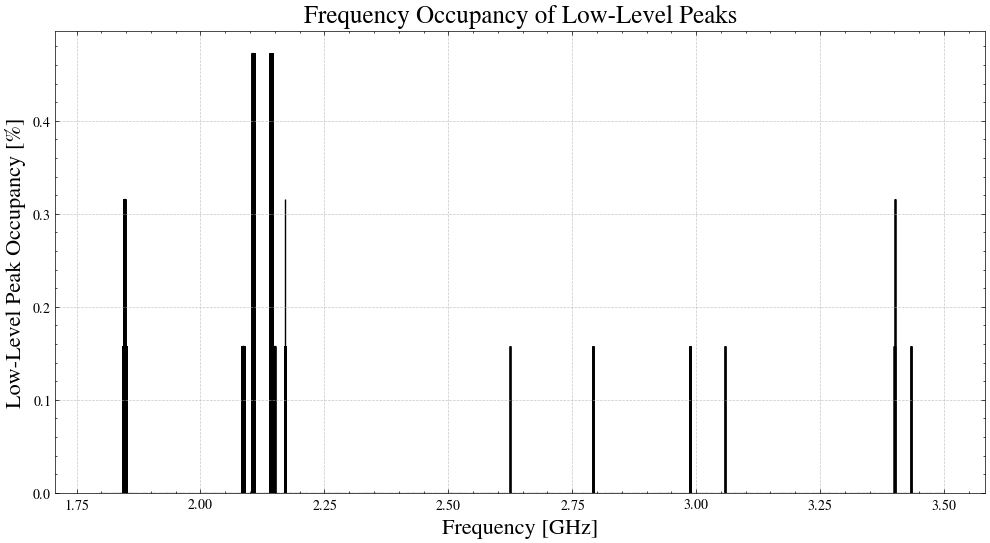

In [42]:
# convert to percentage
occupancy_percentage = (occupancy_counts / n_time) * 100
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


# plot the frequency occupancy of low-level peaks
plt.figure(figsize=(12, 6))
plt.bar(frequency, occupancy_percentage, width=freq_resolution*0.5, align='center', edgecolor='black')
plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Low-Level Peak Occupancy [%]', fontsize=16)
plt.title('Frequency Occupancy of Low-Level Peaks', fontsize=18)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

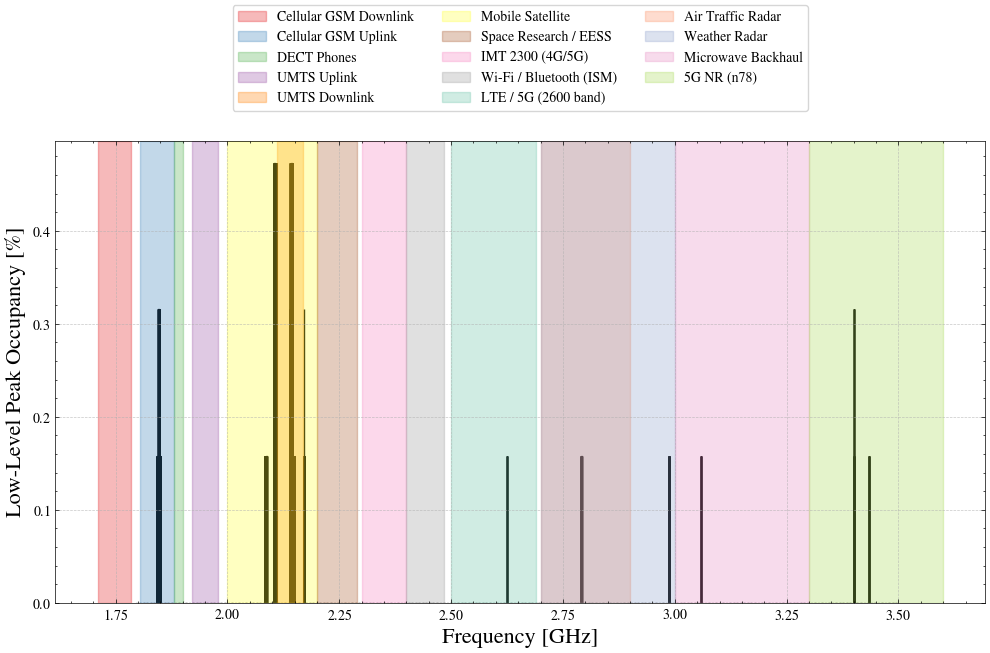

In [43]:


plt.figure(figsize=(12, 6))
plt.bar(frequency,
        occupancy_percentage,
        width=freq_resolution * 0.5,
        align='center',
        edgecolor='black')

# --- Overlay RFI bands ---
for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
    plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Low-Level Peak Occupancy [%]', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(
    bbox_to_anchor=(0.5, 1.05),
    loc='lower center',
    ncol=3,                
    fontsize=10,
    frameon=True
)


#plt.savefig(f'det_asls_plots/low_level_peak_occupancy_{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=120, bbox_inches='tight')

In [ ]:

plt.figure(figsize=(12, 6))
plt.bar(frequency,
        occupancy_percentage,
        width=freq_resolution * 0.5,
        align='center',
        edgecolor='black')

# --- Overlay RFI bands ---
for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
    plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Low-Level Peak Occupancy [%]', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(
    bbox_to_anchor=(0.5, 1.05),
    loc='lower center',
    ncol=3,                
    fontsize=10,
    frameon=True
)


#plt.savefig(f'det_asls_plots/low_level_peak_occupancy_{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=120, bbox_inches='tight')

In [44]:
rfi_bands_sa = {


    # --- Cellular: GSM / LTE 1800 ---
   # "GSM 1800 Uplink": (1.710, 1.785),
    "GSM 1800 Downlink": (1.805, 1.880),

    # --- DECT ---
    "DECT Phones": (1.880, 1.900),

    # --- 3G / UMTS ---
    #"UMTS Uplink": (1.920, 1.980),
    #"UMTS Downlink": (2.110, 2.170),

    # --- S-band Satellite ---
    "MSS S-band Uplink": (1.980, 2.010),
    "MSS S-band Downlink": (2.170, 2.200),
    "Space Research / EESS": (2.200, 2.290),

    # --- IMT2300 ---
    "LTE / 5G (2300 MHz TDD)": (2.300, 2.400),

    # --- ISM Band ---
    "Wi-Fi / ISM": (2.400, 2.4835),        # Industrial, Scientific, Medical
    "Bluetooth": (2.400, 2.480),

    # --- IMT2600 ---
    "LTE / 5G (2600 MHz)": (2.500, 2.690),

   

    # --- Fixed Links ---
    "Microwave Backhaul": (3.000, 3.300),

    # --- 5G Mid-band ---
    "5G NR (n78)": (3.300, 3.700)
}

colors_sa = [
    "#E41A1C",  # red
    "#377EB8",  # blue
    "#4DAF4A",  # green
    "#984EA3",  # purple
    "#FF7F00",  # orange
    "#A65628",  # brown
    "#999999",  # gray
    "#FC8D62",  # salmon
   # "#8DA0CB",  # light blue
   # "#A6D854",  # light green
    "#FFD92F",  # yellow
   # "#1B9E77",  # dark teal
   # "#D95F02"   # dark orange
]

In [45]:
# extract olny frequencies where peaks occured
peak_channels = np.where(occupancy_percentage > 0.2)[0]
print("Detected Peaks Across Full Observation:\n")

for ch in peak_channels:
    print(f"Frequency: {frequency[ch]:.6f} GHz  |  "
          f"Occurrence: {occupancy_percentage[ch]:.2f} %")




Detected Peaks Across Full Observation:

Frequency: 1.845716 GHz  |  Occurrence: 0.32 %
Frequency: 1.845743 GHz  |  Occurrence: 0.32 %
Frequency: 1.845770 GHz  |  Occurrence: 0.32 %
Frequency: 1.845797 GHz  |  Occurrence: 0.32 %
Frequency: 1.845823 GHz  |  Occurrence: 0.32 %
Frequency: 1.845850 GHz  |  Occurrence: 0.32 %
Frequency: 1.845877 GHz  |  Occurrence: 0.32 %
Frequency: 1.845903 GHz  |  Occurrence: 0.32 %
Frequency: 1.845930 GHz  |  Occurrence: 0.32 %
Frequency: 1.845957 GHz  |  Occurrence: 0.32 %
Frequency: 1.845984 GHz  |  Occurrence: 0.32 %
Frequency: 1.846010 GHz  |  Occurrence: 0.32 %
Frequency: 1.846037 GHz  |  Occurrence: 0.32 %
Frequency: 1.846064 GHz  |  Occurrence: 0.32 %
Frequency: 1.846090 GHz  |  Occurrence: 0.32 %
Frequency: 1.846117 GHz  |  Occurrence: 0.32 %
Frequency: 1.846144 GHz  |  Occurrence: 0.32 %
Frequency: 1.846170 GHz  |  Occurrence: 0.32 %
Frequency: 1.846197 GHz  |  Occurrence: 0.32 %
Frequency: 1.846224 GHz  |  Occurrence: 0.32 %
Frequency: 1.846251

In [46]:
#sorted by higest Persistence

sorted_indices = peak_channels[np.argsort(occupancy_percentage[peak_channels])[::-1]]

print("Persistent RFI Frequencies (sorted by occurrence):\n")

for ch in sorted_indices:
    print(f"{frequency[ch]:.6f} GHz  -->  {occupancy_percentage[ch]:.2f} %")


Persistent RFI Frequencies (sorted by occurrence):

2.104628 GHz  -->  0.47 %
2.104654 GHz  -->  0.47 %
2.104681 GHz  -->  0.47 %
2.104708 GHz  -->  0.47 %
2.104734 GHz  -->  0.47 %
2.104761 GHz  -->  0.47 %
2.104788 GHz  -->  0.47 %
2.104815 GHz  -->  0.47 %
2.104841 GHz  -->  0.47 %
2.104868 GHz  -->  0.47 %
2.104895 GHz  -->  0.47 %
2.104921 GHz  -->  0.47 %
2.104948 GHz  -->  0.47 %
2.104975 GHz  -->  0.47 %
2.105001 GHz  -->  0.47 %
2.143801 GHz  -->  0.47 %
2.143827 GHz  -->  0.47 %
2.143854 GHz  -->  0.47 %
2.143881 GHz  -->  0.47 %
2.143908 GHz  -->  0.47 %
2.143934 GHz  -->  0.47 %
2.143961 GHz  -->  0.47 %
2.143988 GHz  -->  0.47 %
2.144014 GHz  -->  0.47 %
2.144041 GHz  -->  0.47 %
2.144068 GHz  -->  0.47 %
2.144094 GHz  -->  0.47 %
2.144121 GHz  -->  0.47 %
2.144148 GHz  -->  0.47 %
2.144175 GHz  -->  0.47 %
2.144201 GHz  -->  0.47 %
2.143373 GHz  -->  0.47 %
2.143400 GHz  -->  0.47 %
2.143427 GHz  -->  0.47 %
2.143454 GHz  -->  0.47 %
2.143480 GHz  -->  0.47 %
2.143507 GHz

# Evaluate the low level RFI


Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


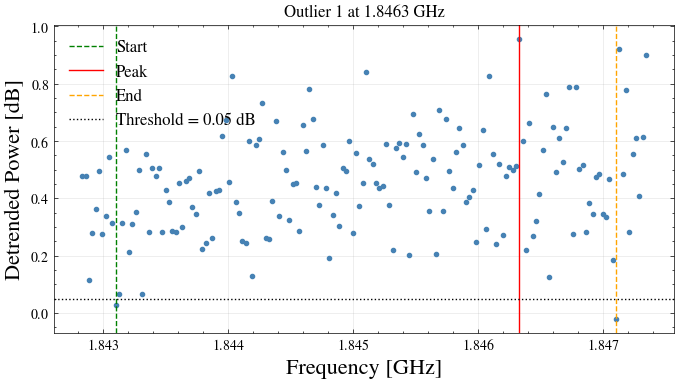


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


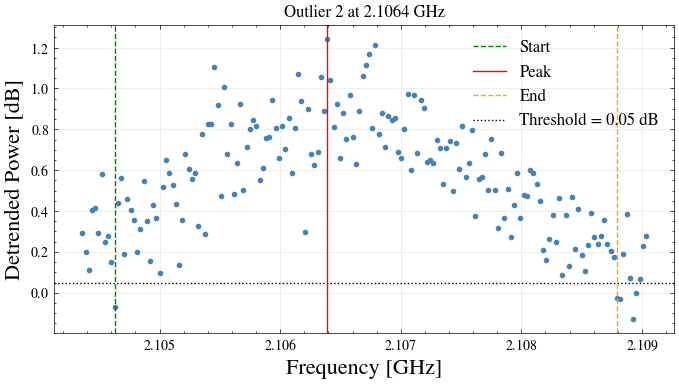


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


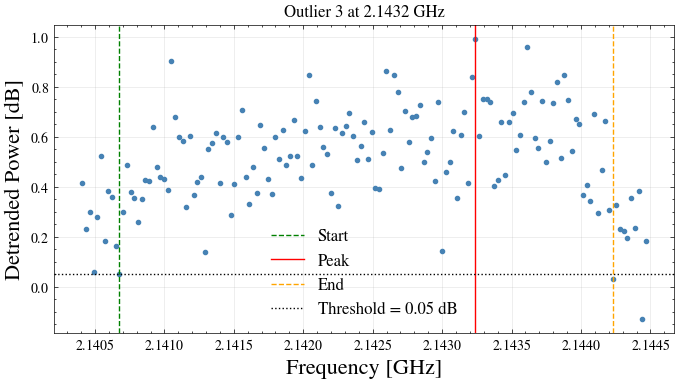


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


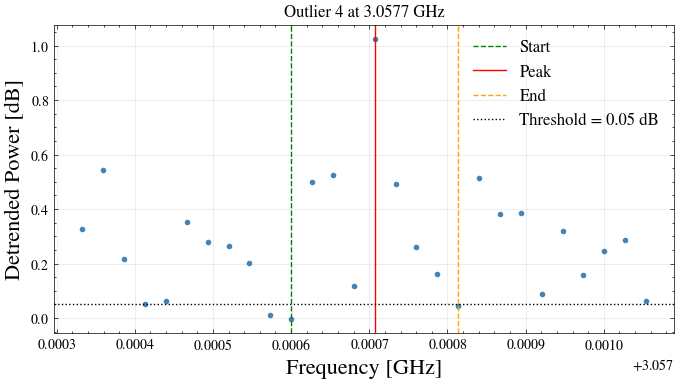

In [47]:
peak_freqs_low = frequency[peaks_low]

results_low_outliers = quantify_all_outliers(
    freq=frequency,
    power=clean_spec,
    peak_freqs=peak_freqs_low,
    threshold=0.05,
    plot=True
)


Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


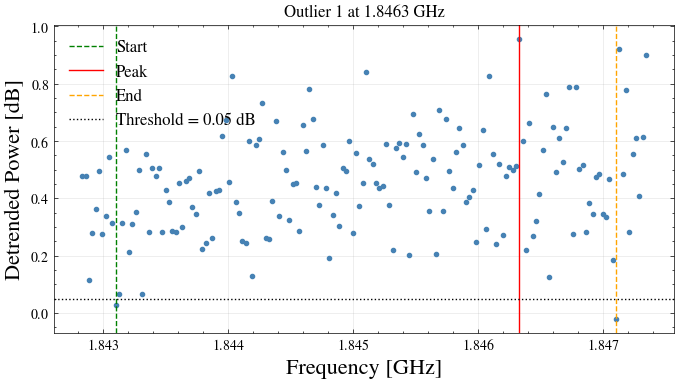


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


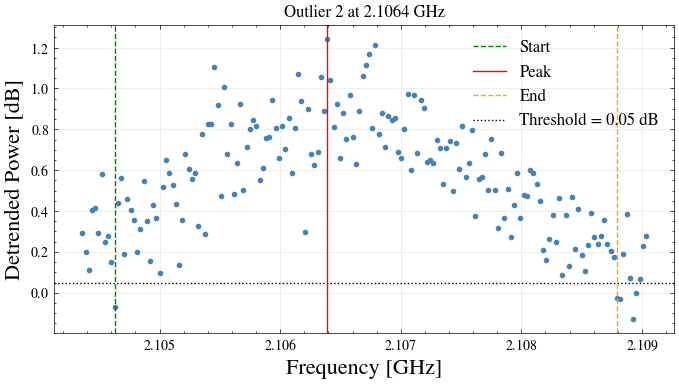


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


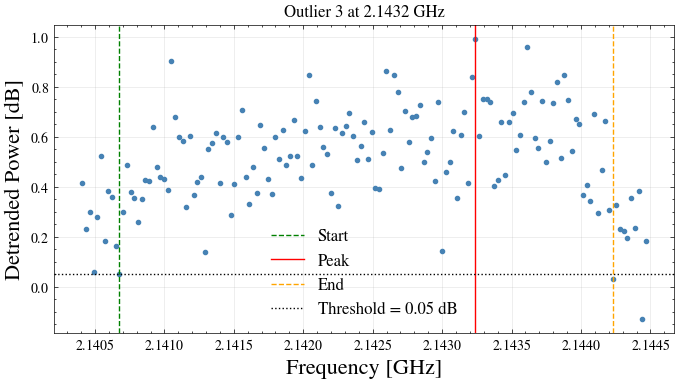


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


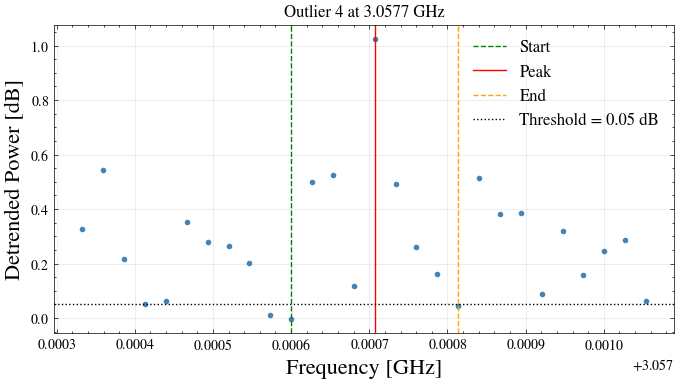


Peaks detected at [14:58:58]: ['1.8196', '2.0028', '2.1416', '2.1841', '2.2000', '2.3629', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


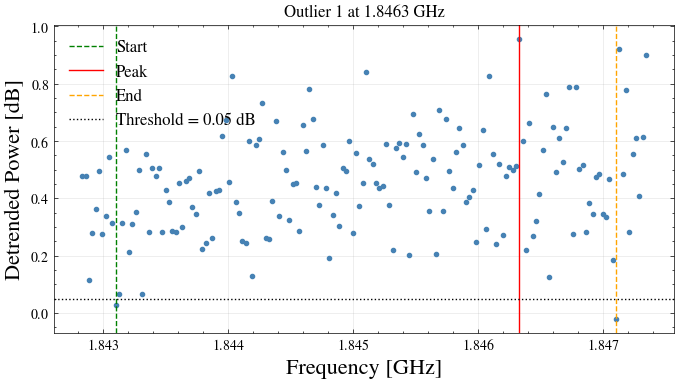


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


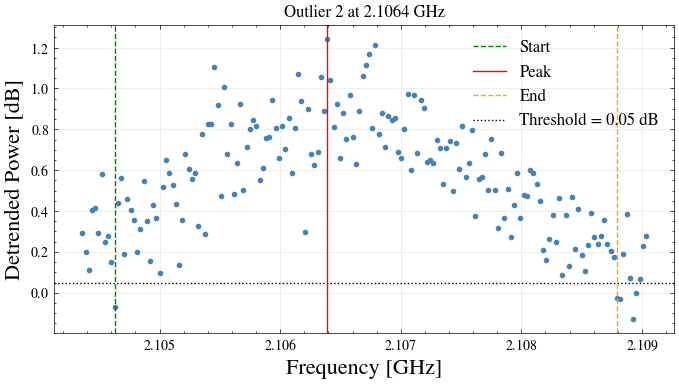


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


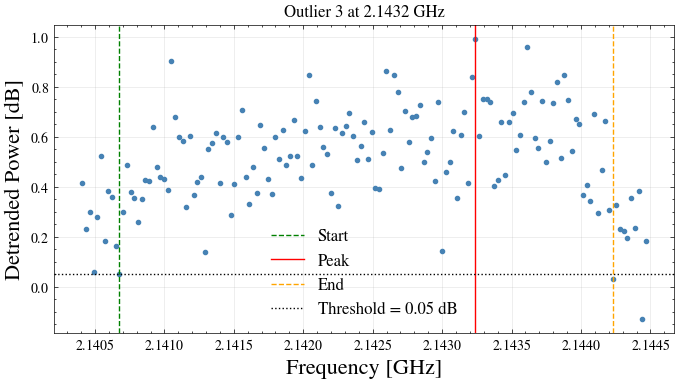


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


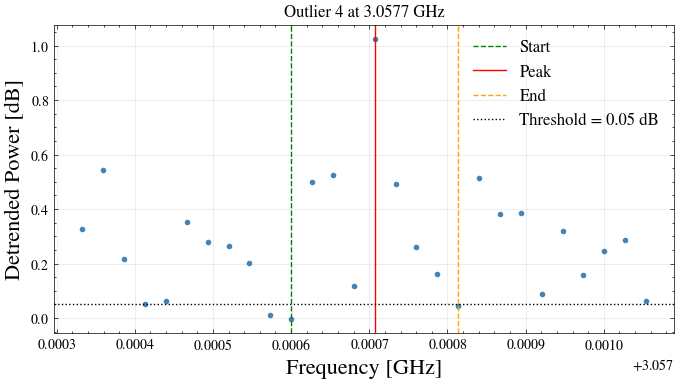


Peaks detected at [14:59:13]: ['1.8196', '2.0028', '2.1839', '2.2000', '2.3628', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


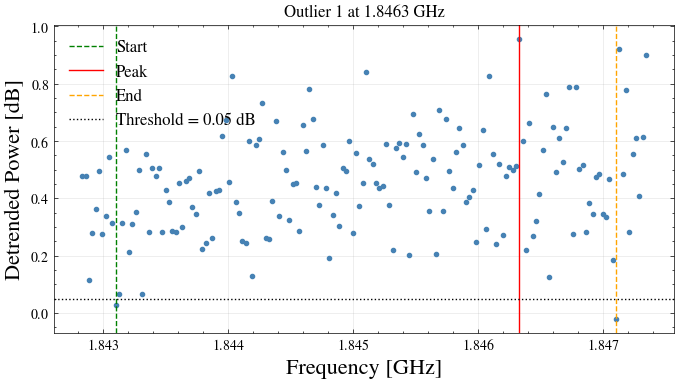


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


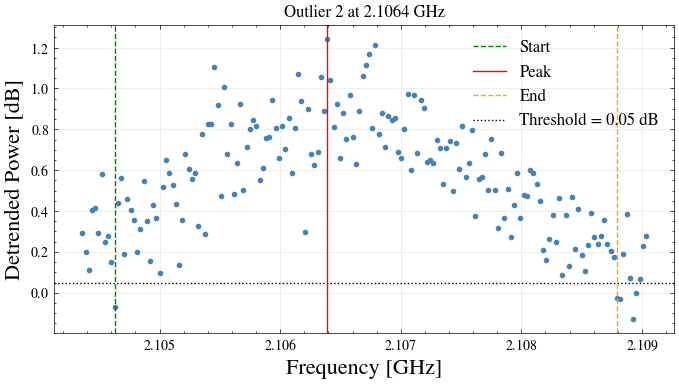


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


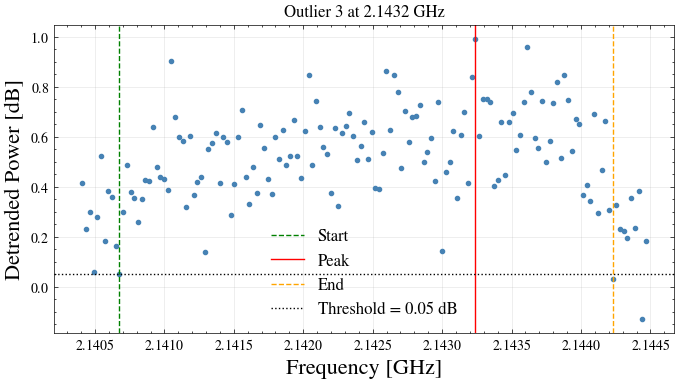


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


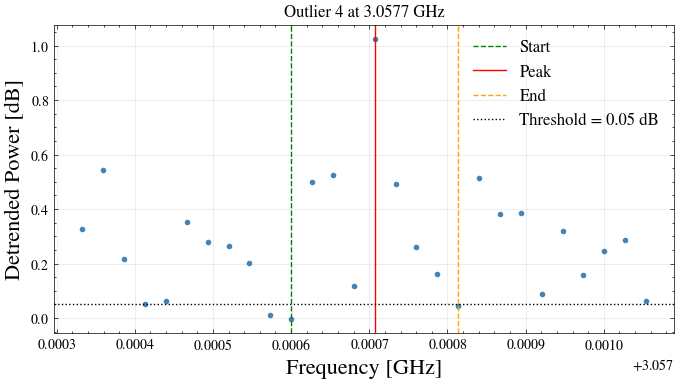


Peaks detected at [14:59:28]: ['1.8196', '2.0028', '2.1999', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


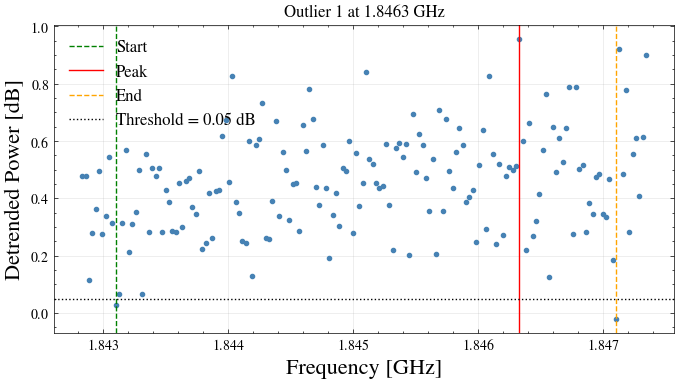


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


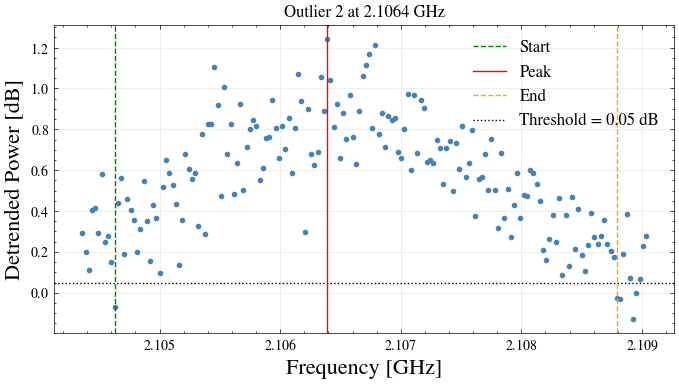


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


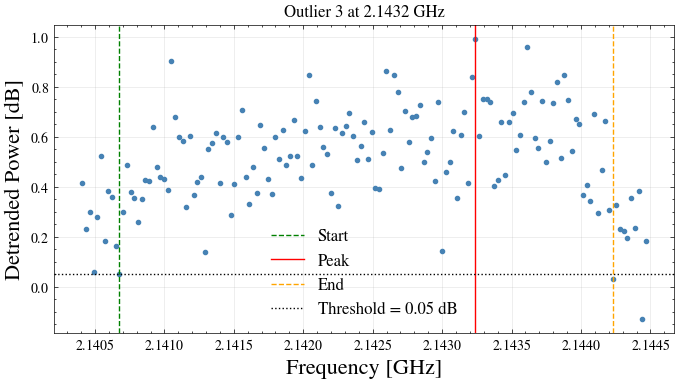


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


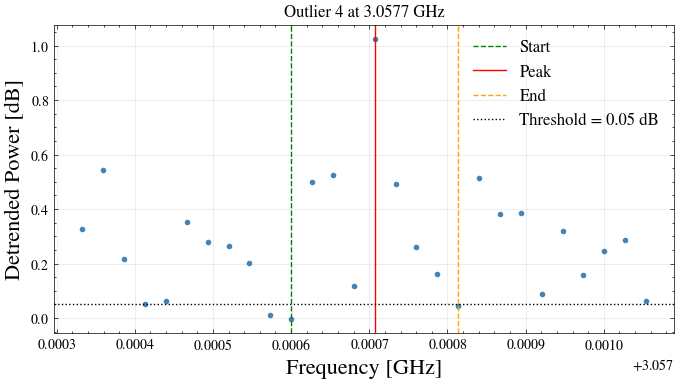


Peaks detected at [14:59:43]: ['1.8197', '2.0028', '2.1707', '2.1999', '2.3628', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


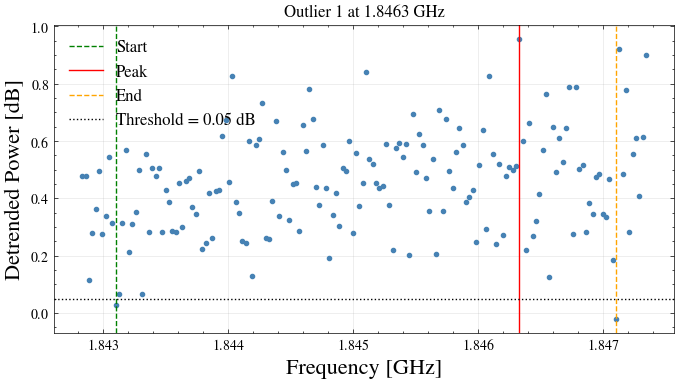


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


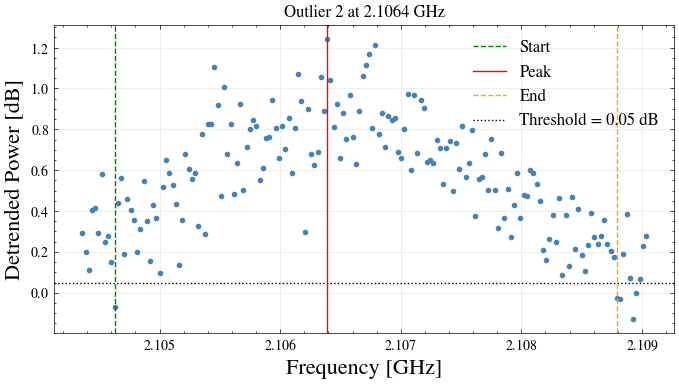


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


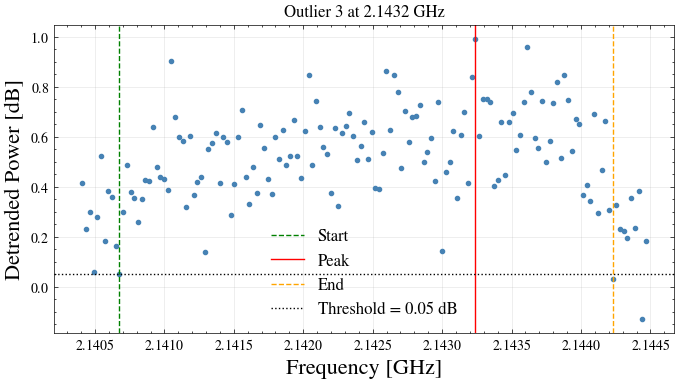


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


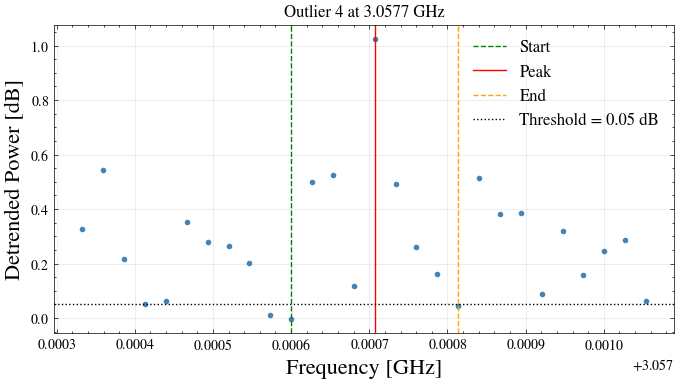


Peaks detected at [14:59:58]: ['1.8196', '2.0028', '2.1061', '2.1841', '2.1999', '2.3628', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


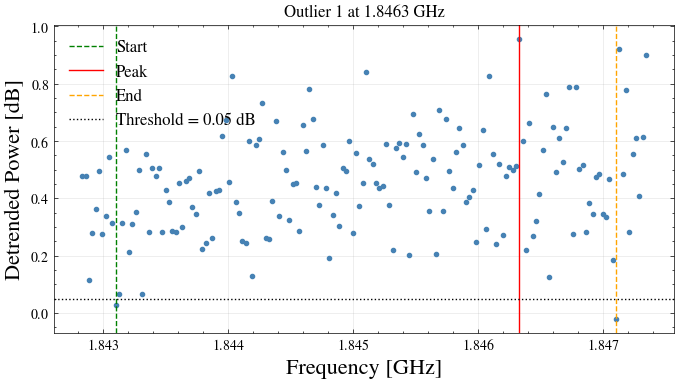


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


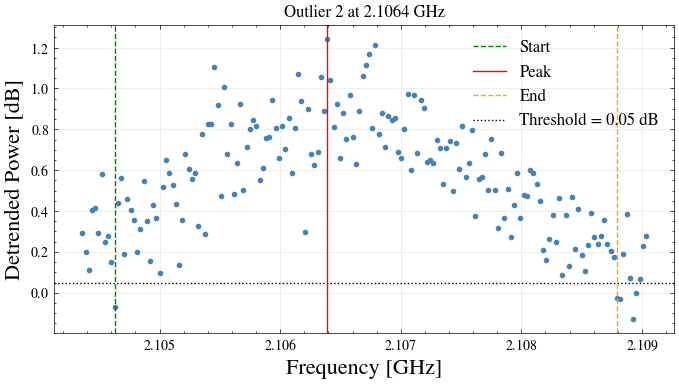


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


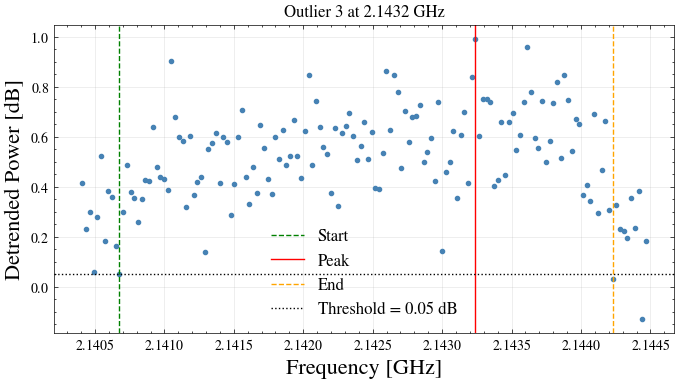


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


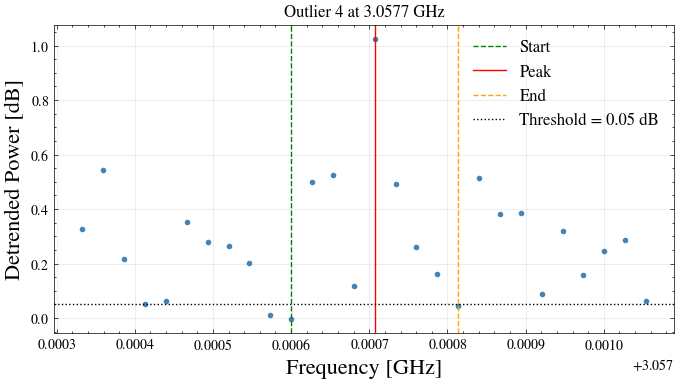


Peaks detected at [15:00:13]: ['1.8196', '2.0028', '2.1845', '2.1999', '2.3626', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


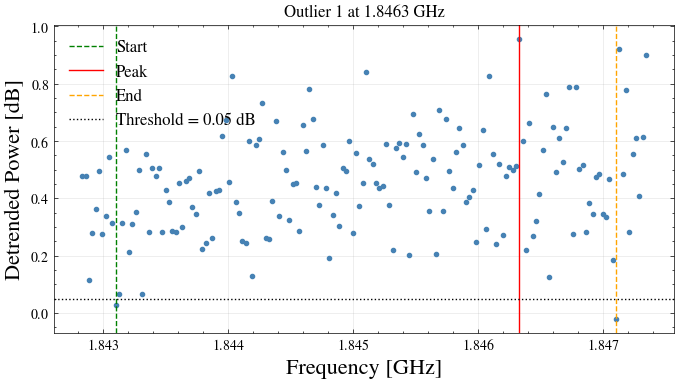


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


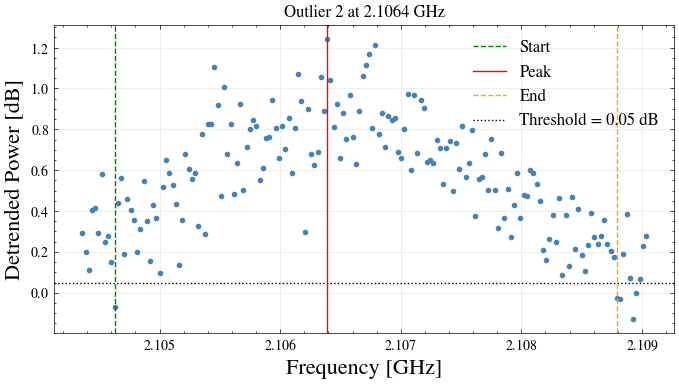


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


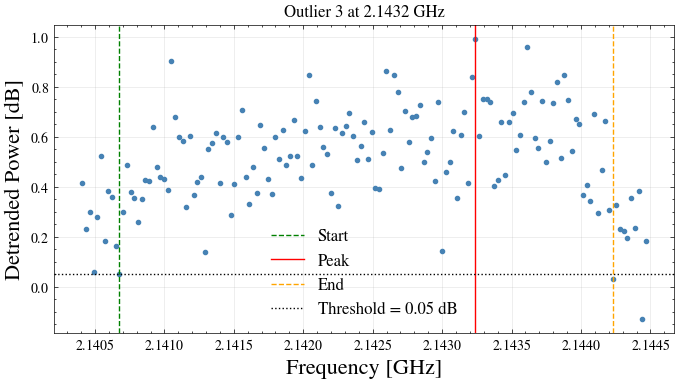


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


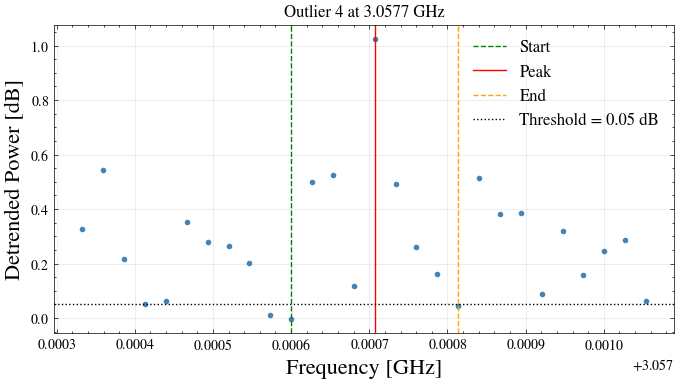

In [48]:
results_low_all_times = []

for res in results_all_times:

    # --- Extract information for this time bin ---
    time_label = res["time_label"]
    det_spec = res["det_spec"]
    peak_freqs = res["peak_freqs"]

    # --- Print detected peaks ---
    formatted_freqs = [f"{f:.4f}" for f in peak_freqs]

    print(f"\nPeaks detected at [{time_label}]: {formatted_freqs} GHz")

    # --- Quantify bandwidth affected by each peak ---
    results_low_outliers = quantify_all_outliers(
    freq=frequency,
    power=clean_spec,
    peak_freqs=peak_freqs_low,
    threshold=0.05,
    plot=True
)

    # --- Store results for this time bin ---
    results_low_all_times.append({
        "time_label": time_label,
        "time_index": res["time_index"],
        "outliers": results_low_outliers
    })


Outlier 1:
  Peak Frequency : 1.8463 GHz
  Peak Power     : 0.9567 dB
  Start Frequency: 1.8431 GHz
  End Frequency  : 1.8471 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels


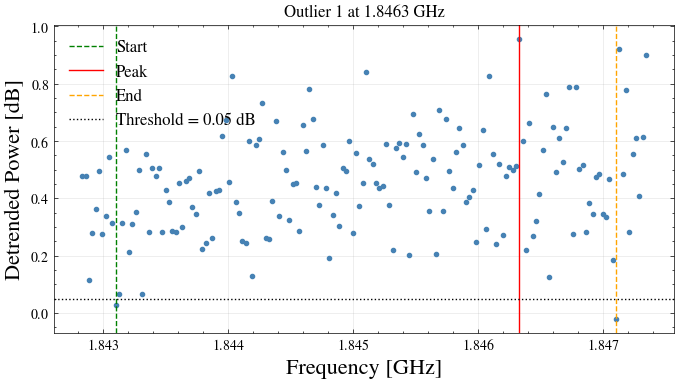


Outlier 2:
  Peak Frequency : 2.1064 GHz
  Peak Power     : 1.2405 dB
  Start Frequency: 2.1046 GHz
  End Frequency  : 2.1088 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 156 channels


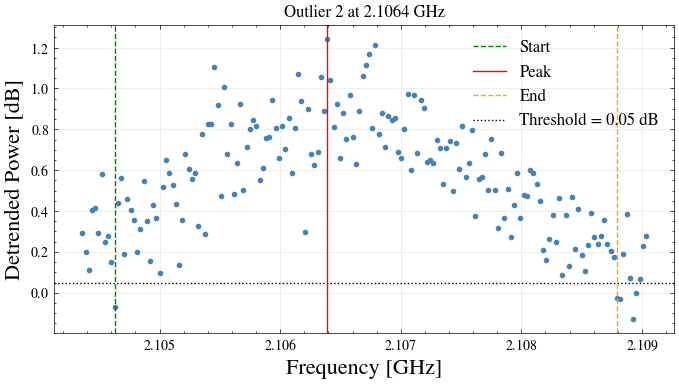


Outlier 3:
  Peak Frequency : 2.1432 GHz
  Peak Power     : 0.9918 dB
  Start Frequency: 2.1407 GHz
  End Frequency  : 2.1442 GHz
  Bandwidth      : 0.0036 GHz
  Corrupted Ch.  : 133 channels


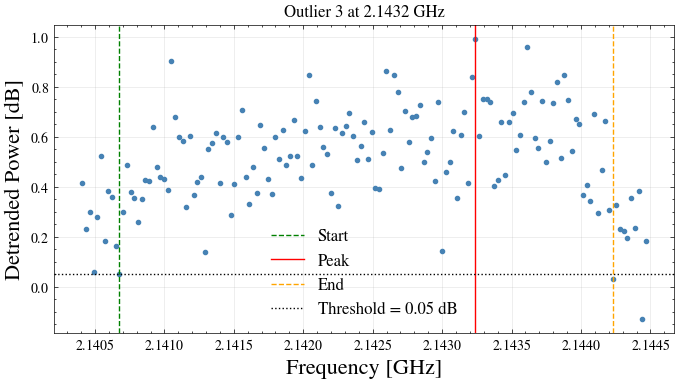


Outlier 4:
  Peak Frequency : 3.0577 GHz
  Peak Power     : 1.0247 dB
  Start Frequency: 3.0576 GHz
  End Frequency  : 3.0578 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels


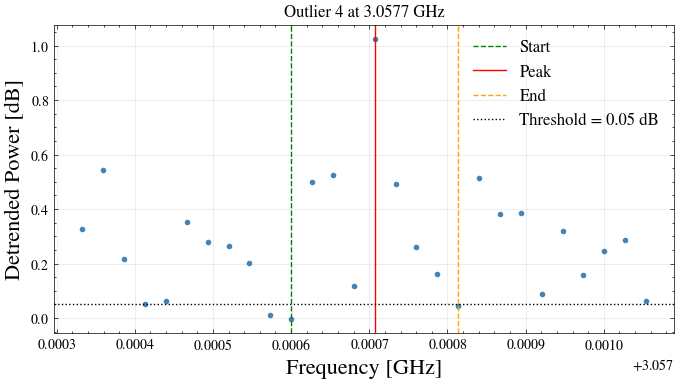

In [49]:
peak_freqs_low = frequency[peaks_low]

results_low_outliers = quantify_all_outliers(
    freq=frequency,
    power=clean_spec,
    peak_freqs=peak_freqs_low,
    threshold=0.05,
    plot=True
)

### Represent the RFI occupanu in polar plot

It can be quite effective for showing how much of the spectrum is contaminated. The idea is:

Angle (θ) → Frequency across your band (1.75–3.5 GHz)

Radius (r) → Percentage of time the channel is affected (occupancy)

Colored sectors → Known RFI bands

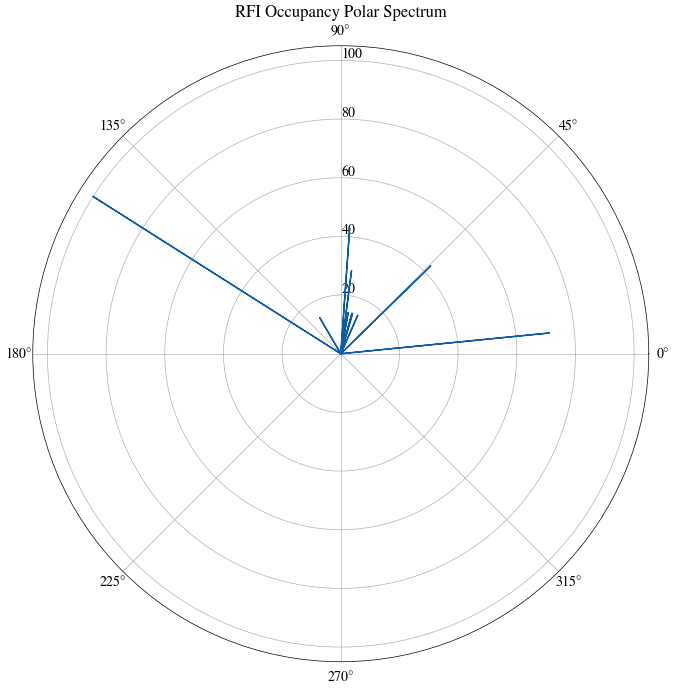

In [50]:
f_min = frequency.min()
f_max = frequency.max()

theta = 2 * np.pi * (frequency - f_min) / (f_max - f_min)


fig = plt.figure(figsize=(8,8))
ax = plt.subplot(111, projection='polar')

# radius = occupancy percentage
r = percentage

ax.plot(theta, r, linewidth=1)

ax.set_title("RFI Occupancy Polar Spectrum")
ax.set_rlabel_position(90)

plt.show()

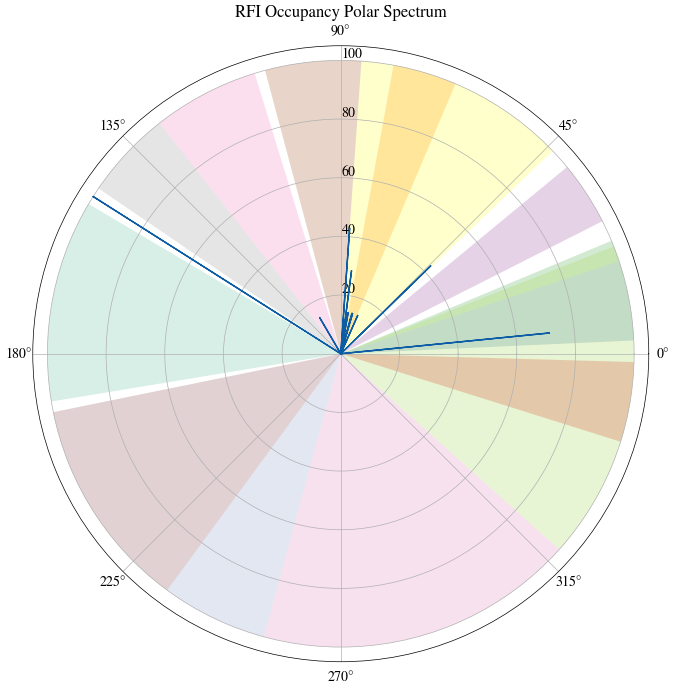

In [51]:

fig = plt.figure(figsize=(8,8))
ax = plt.subplot(111, projection='polar')

# radius = occupancy percentage
r = percentage


ax.plot(theta, r, linewidth=1)


for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):

    theta_start = 2*np.pi*(f_start - f_min)/(f_max - f_min)
    theta_end   = 2*np.pi*(f_end   - f_min)/(f_max - f_min)

    ax.bar(
        x=(theta_start + theta_end)/2,
        height=100,
        width=(theta_end - theta_start),
        bottom=0,
        color=color,
        alpha=0.25,
        edgecolor=None
    )

ax.set_title("RFI Occupancy Polar Spectrum")
ax.set_rlabel_position(90)

plt.show()

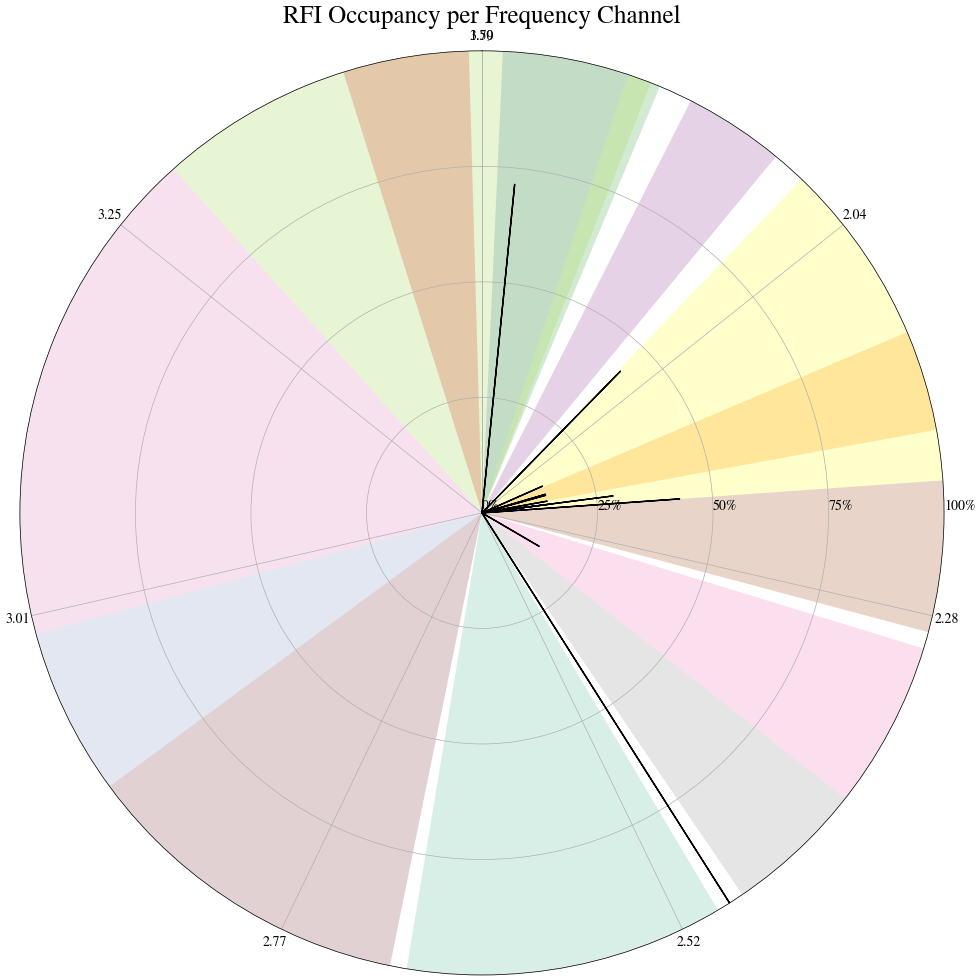

In [52]:


# Convert frequency to polar angle
theta = 2*np.pi*(frequency - f_min)/(f_max - f_min)

# Radius = occupancy
r = percentage

fig = plt.figure(figsize=(10,10))
ax = plt.subplot(111, projection='polar')

# --- Plot occupancy ---
ax.plot(theta, r, color='black', linewidth=1)

# Fill for visual clarity
ax.fill_between(theta, 0, r, alpha=0.4)

# --- Polar formatting ---
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

ax.set_ylim(0,100)

ax.set_title(
    "RFI Occupancy per Frequency Channel",
    fontsize=18,
    pad=20
)

# --- Plot RFI bands ---
colors = [
"#E41A1C","#377EB8","#4DAF4A","#984EA3","#FF7F00",
"#FFFF33","#A65628","#F781BF","#999999","#66C2A5",
"#FC8D62","#8DA0CB","#E78AC3","#A6D854","#FFD92F",
"#E5C494","#B3B3B3"
]

for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):

    theta_start = 2*np.pi*(f_start - f_min)/(f_max - f_min)
    theta_end   = 2*np.pi*(f_end   - f_min)/(f_max - f_min)

    ax.bar(
        x=(theta_start + theta_end)/2,
        height=100,
        width=(theta_end - theta_start),
        bottom=0,
        color=color,
        alpha=0.25
    )

# --- Radial labels ---
ax.set_rlabel_position(90)
ax.set_yticks([0,25,50,75,100])
ax.set_yticklabels(["0%","25%","50%","75%","100%"])

freq_ticks = np.linspace(f_min, f_max, 8)
theta_ticks = 2*np.pi*(freq_ticks - f_min)/(f_max - f_min)

ax.set_xticks(theta_ticks)
ax.set_xticklabels([f"{f:.2f}" for f in freq_ticks])

plt.tight_layout()

# # --- Save ---
# plt.savefig("RFI_polar_occupancy.png", dpi=300)
# plt.savefig("RFI_polar_occupancy.pdf")

# plt.show()

In [53]:
ds_nd1 = datasets[1]
spectrum_nd = 10 * np.log10(ds_nd1['spectrum'].values)**2

frequency_nd = ds_nd1['frequency'].values/1e9  # convert to GHz
time = ds_nd1['time']
time_utc = pd.to_datetime(time.values, unit='s', origin='unix')

spectrum_nd.shape, frequency_nd.shape, time_utc.shape

((1, 634, 63877), (63877,), (634,))

Peaks detected at [14:58:43]: ['1.8197', '1.8225', '2.0028', '2.1063', '2.1431', '2.1463', '2.1490', '2.2000', '2.3632', '2.4920'] GHz


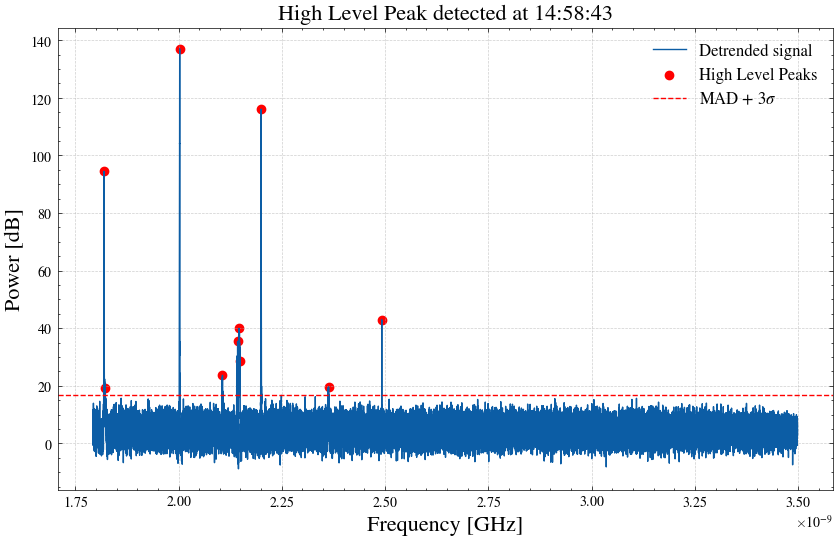

In [54]:


for i in itime_target:
    # Detrend / baseline correct the spectrum at this time
    det_spec_itime = base_correction(frequency_nd, spectrum_nd[0, i, :])


    sigma_value_high = 3
    # Detect peaks
    threshold = MAD(det_spec_itime) + sigma_value_high * np.std(det_spec_itime)
    peaks, properties = find_peaks(det_spec_itime,
                                   height=threshold,
                                   prominence=1.5,
                                   distance=100
                                   )

    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(frequency_nd, det_spec_itime, label=f'Detrended signal')
    plt.scatter(frequency_nd[peaks], det_spec_itime[peaks], color='red', label='High Level Peaks')
    plt.axhline(y=threshold, color='red', linestyle='--', label=f'MAD + {sigma_value_high}$σ$')

    plt.title(f'High Level Peak detected at {time_utc[i].strftime("%H:%M:%S")}', fontsize=16)
    plt.xlabel('Frequency [GHz]',fontsize=16)
    plt.ylabel('Power [dB]',fontsize=16)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=12)

    #plt.xlim(2.358,2.365)



    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]

    print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    plt.show()
    


    break